# Module 05 — Optimisation

This notebook is the runnable companion to the [concept guide](README.md) — read the guide first, or
keep it open alongside. Everything here is built from scratch in NumPy: gradient descent on an
ill-conditioned bowl (including a run that diverges), the convergence rate as a function of the
condition number, mini-batch SGD and its noise floor, momentum / RMSProp / Adam on the Rosenbrock
function and on a real logistic-regression problem, Newton's method, Lagrange multipliers as a
picture, and the diagnostics (schedules, range test, clipping, early stopping) you use in practice.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. The optimisation problem: landscapes, minima and saddles

Training minimises an empirical risk $L(\theta) = \frac1n\sum_i \ell(f_\theta(x_i), y_i)$. The
simplest possible instance: fit $y \approx w x$ to three points by mean squared error. In one
dimension you can see the whole landscape, so we plot it and check that the derivative changes
sign exactly at the minimiser $w^\star = \sum x_i y_i / \sum x_i^2$.

A *stationary* point has $\nabla L = 0$, but that is not enough to be a minimum: on
$f(x, y) = x^2 - y^2$ the origin is stationary and is a **saddle** — downhill along $y$, uphill
along $x$. Gradient descent started exactly on a saddle never moves; started anywhere nearby it
slides off along the negative-curvature direction.

w = 1.50   L(w) = 1.3533   dL/dw = -5.000
w = 2.00   L(w) = 0.0200   dL/dw = -0.333
w = 2.10   L(w) = 0.0333   dL/dw = +0.600
closed form: w* = 2.0357,  L(w*) = 0.0140,  dL/dw(w*) = +1.8e-15


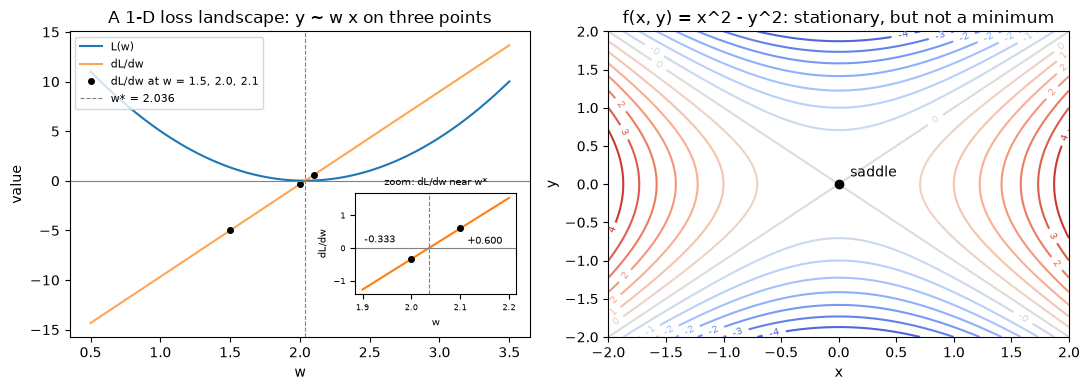

In [2]:
x = np.array([1., 2., 3.])
y = np.array([2.1, 3.9, 6.2])

def loss_1d(w):
    return np.mean((w * x - y) ** 2)

def dloss_1d(w):
    return np.mean(2 * x * (w * x - y))

w_star = (x @ y) / (x @ x)
for w in [1.5, 2.0, 2.1]:
    print(f"w = {w:4.2f}   L(w) = {loss_1d(w):.4f}   dL/dw = {dloss_1d(w):+.3f}")
print(f"closed form: w* = {w_star:.4f},  L(w*) = {loss_1d(w_star):.4f},  dL/dw(w*) = {dloss_1d(w_star):+.1e}")

ws = np.linspace(0.5, 3.5, 300)
w_tab = np.array([1.5, 2.0, 2.1])                      # the three tabulated points
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ws, [loss_1d(w) for w in ws], label="L(w)")
ax[0].plot(ws, [dloss_1d(w) for w in ws], label="dL/dw", alpha=0.7)
ax[0].plot(w_tab, [dloss_1d(w) for w in w_tab], "ko", ms=4, label="dL/dw at w = 1.5, 2.0, 2.1")
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].axvline(w_star, color="gray", ls="--", lw=0.8, label=f"w* = {w_star:.3f}")
ax[0].set_title("A 1-D loss landscape: y ~ w x on three points")
ax[0].set_xlabel("w"); ax[0].set_ylabel("value"); ax[0].legend(fontsize=8, loc="upper left")
# zoom on the sign change of dL/dw between w = 2.0 and w = 2.1
inset = ax[0].inset_axes([0.62, 0.14, 0.35, 0.33])
wz = np.linspace(1.9, 2.2, 50)
inset.plot(wz, [dloss_1d(w) for w in wz], color="C1")
inset.plot(w_tab[1:], [dloss_1d(w) for w in w_tab[1:]], "ko", ms=4)
for w in w_tab[1:]:
    inset.annotate(f"{dloss_1d(w):+.3f}", (w, dloss_1d(w)), textcoords="offset points",
                   xytext=(-34, 12) if w < w_star else (5, -11), fontsize=7)
inset.axhline(0, color="gray", lw=0.8); inset.axvline(w_star, color="gray", ls="--", lw=0.8)
inset.set_title("zoom: dL/dw near w*", fontsize=7); inset.set_xlabel("w", fontsize=7); inset.set_ylabel("dL/dw", fontsize=7)
inset.tick_params(labelsize=6)

X, Y = np.meshgrid(np.linspace(-2, 2, 101), np.linspace(-2, 2, 101))
cs = ax[1].contour(X, Y, X ** 2 - Y ** 2, levels=np.linspace(-4, 4, 17), cmap="coolwarm")
ax[1].clabel(cs, fmt="%.0f", fontsize=7)
ax[1].plot(0, 0, "ko"); ax[1].annotate("saddle", (0.1, 0.1))
ax[1].set_title("f(x, y) = x^2 - y^2: stationary, but not a minimum")
ax[1].set_xlabel("x"); ax[1].set_ylabel("y")
plt.tight_layout(); plt.show()

Notice that the derivative is negative at $w = 2.0$ and positive at $w = 2.1$: the minimiser
$w^\star = 2.036$ sits between them, exactly where $\mathrm{d}L/\mathrm{d}w$ crosses zero. On the
right, the contours of $x^2 - y^2$ form a cross at the origin: the Hessian $\mathrm{diag}(2, -2)$
has one positive and one negative eigenvalue. In high dimensions saddles are far more common than
local minima, and most "the loss has plateaued" moments in deep learning are slow passages near
saddles, not convergence.

What does gradient descent actually do near that saddle? The gradient is $(2x, -2y)$, so one step with
step size $\eta$ multiplies $x$ by $1 - 2\eta$ and $y$ by $1 + 2\eta$. We start four runs at $x_0 = 1.5$,
at different small distances $y_0$ from the $x$-axis, and follow both the path and the loss.

y0 = +0.3: |y| reaches 1 after about ln(1/|y0|)/ln(1.2) = 7 steps
y0 = +0.01: |y| reaches 1 after about ln(1/|y0|)/ln(1.2) = 25 steps
y0 = -0.0001: |y| reaches 1 after about ln(1/|y0|)/ln(1.2) = 51 steps
y0 = 0    : after 90 steps the iterate is at [0. 0.] -- stuck on the saddle


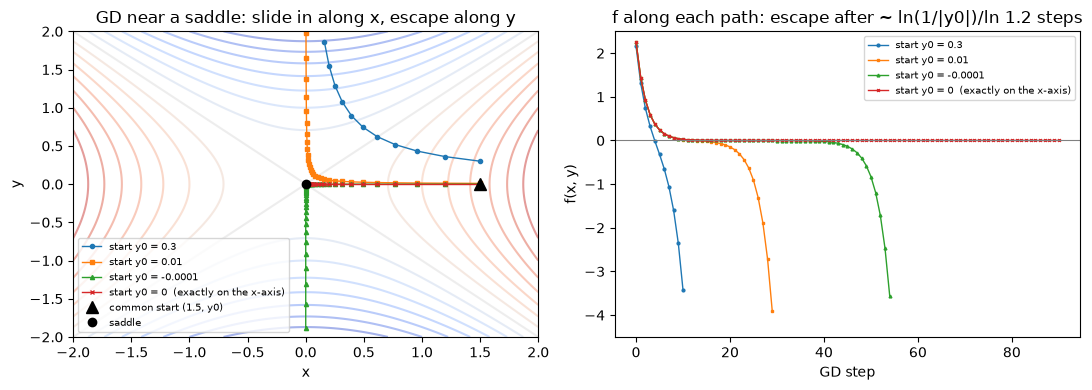

In [3]:
eta_sad = 0.1                                   # x shrinks by 1 - 2 eta = 0.8 per step, y grows by 1 + 2 eta = 1.2
Xs, Ys = np.meshgrid(np.linspace(-2, 2, 101), np.linspace(-2, 2, 101))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].contour(Xs, Ys, Xs ** 2 - Ys ** 2, levels=np.linspace(-4, 4, 17), cmap="coolwarm", alpha=0.5)
for y0, mk in [(0.3, "o"), (1e-2, "s"), (-1e-4, "^"), (0.0, "x")]:
    p = np.array([1.5, y0]); path_sad = [p]
    for _ in range(90):
        p = p - eta_sad * np.array([2 * p[0], -2 * p[1]]); path_sad.append(p)
    path_sad = np.array(path_sad); keep = np.abs(path_sad[:, 1]) <= 2        # stop drawing once the run has left the box
    lab = f"start y0 = {y0:g}" + ("  (exactly on the x-axis)" if y0 == 0 else "")
    ax[0].plot(path_sad[keep, 0], path_sad[keep, 1], marker=mk, ms=3, lw=1, label=lab)
    ax[1].plot(np.flatnonzero(keep), (path_sad[:, 0] ** 2 - path_sad[:, 1] ** 2)[keep], marker=mk, ms=2, lw=1, label=lab)
    if y0 != 0:
        print(f"y0 = {y0:+g}: |y| reaches 1 after about ln(1/|y0|)/ln(1.2) = {np.log(1 / abs(y0)) / np.log(1 + 2 * eta_sad):.0f} steps")
    else:
        print(f"y0 = 0    : after 90 steps the iterate is at {path_sad[-1]} -- stuck on the saddle")
ax[0].plot(1.5, 0, "k^", ms=8, label="common start (1.5, y0)"); ax[0].plot(0, 0, "ko", label="saddle")
ax[0].set_title("GD near a saddle: slide in along x, escape along y"); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[0].legend(fontsize=7, loc="lower left")
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_title("f along each path: escape after ~ ln(1/|y0|)/ln 1.2 steps"); ax[1].set_xlabel("GD step"); ax[1].set_ylabel("f(x, y)")
ax[1].set_ylim(-4.5, 2.5); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Notice that** the start exactly on the $x$-axis slides into the saddle and stays there for ever,
while every other start first slides in ($x$ shrinks by $1 - 2\eta = 0.8$ per step) and then escapes
along $y$, which grows by $1 + 2\eta = 1.2$ per step. The loss falls to near $f = 0$ and stays there
until the escape, when $\lvert y\rvert$ reaches 1 (and $f \approx -1$) after about
$\ln(1/\lvert y_0\rvert)/\ln 1.2$ steps: 25 and 51 for the two small $y_0$, but only 7 for $y_0 = 0.3$, so
early that there is hardly a plateau. The closer a run passes a saddle, the longer it looks converged.
The sign of $y_0$ only decides which way it leaves.

## 2. Convexity: the Hessian test and Jensen's inequality

A twice-differentiable function is convex iff its Hessian is positive semi-definite everywhere,
$\nabla^2 f \succeq 0$. We test this numerically by estimating the Hessian with finite differences
at many random points and recording the *smallest* eigenvalue:

* the logistic loss of a linear classifier, $\frac1n\sum_i \log(1 + e^{-\tilde y_i (w_0 + w_1 x_i)})$,
  has Hessian $\frac1n X^\top S X$ with $S_{ii} = p_i(1-p_i) \ge 0$ — convex;
* a one-neuron "network" $a \tanh(w x)$ with squared loss is **not** convex.

We also check Jensen's inequality $f(\mathbb{E}[X]) \le \mathbb{E}[f(X)]$ for $f(x) = x^2$ with a random
discrete distribution.

logistic loss : smallest Hessian eigenvalue over 60 points = +0.0033  (never negative)
tiny tanh net : smallest Hessian eigenvalue over 60 points = -5.6214  (negative at 43 of 60 points)
Jensen for x^2:  f(E[X]) = 0.2127  <=  E[f(X)] = 1.1582   gap = Var(X) = 0.9455


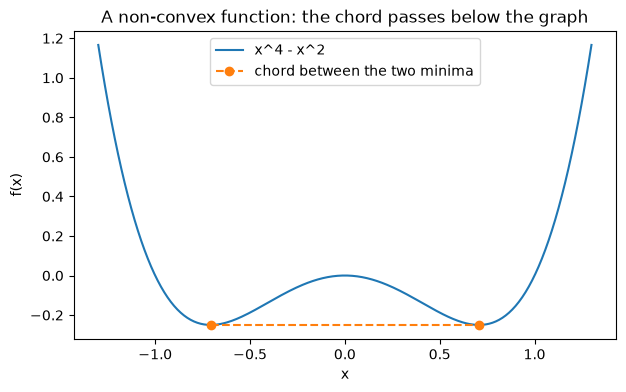

In [4]:
n = 40
x1 = rng.normal(size=n)
y_cls = (x1 + 0.5 * rng.normal(size=n) > 0).astype(float)      # labels in {0, 1}
y_pm = 2 * y_cls - 1                                            # the same labels in {-1, +1}

def logistic_loss(w):
    z = w[0] + w[1] * x1
    return np.mean(np.logaddexp(0.0, -y_pm * z))

def tiny_net_loss(theta):
    a, w = theta
    return np.mean((a * np.tanh(w * x1) - y_pm) ** 2)

def numerical_hessian(f, p, h=1e-4):
    p = np.asarray(p, dtype=float); d = len(p); H = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            ei = np.zeros(d); ei[i] = h
            ej = np.zeros(d); ej[j] = h
            H[i, j] = (f(p + ei + ej) - f(p + ei - ej) - f(p - ei + ej) + f(p - ei - ej)) / (4 * h * h)
    return H

points = rng.normal(size=(60, 2)) * 2.0
min_eig_logistic = [np.linalg.eigvalsh(numerical_hessian(logistic_loss, p))[0] for p in points]
min_eig_net = [np.linalg.eigvalsh(numerical_hessian(tiny_net_loss, p))[0] for p in points]
print(f"logistic loss : smallest Hessian eigenvalue over 60 points = {min(min_eig_logistic):+.4f}  (never negative)")
print(f"tiny tanh net : smallest Hessian eigenvalue over 60 points = {min(min_eig_net):+.4f}  "
      f"(negative at {sum(m < -1e-8 for m in min_eig_net)} of 60 points)")

# Jensen's inequality for f(x) = x^2 and a random discrete distribution
vals = rng.normal(size=6); probs = rng.dirichlet(np.ones(6))
lhs = (probs @ vals) ** 2; rhs = probs @ vals ** 2
print(f"Jensen for x^2:  f(E[X]) = {lhs:.4f}  <=  E[f(X)] = {rhs:.4f}   gap = Var(X) = {rhs - lhs:.4f}")

# the two minima of x^4 - x^2 and the chord between them
xx = np.linspace(-1.3, 1.3, 300); f4 = xx ** 4 - xx ** 2
plt.plot(xx, f4, label="x^4 - x^2")
xa, xb = -1 / np.sqrt(2), 1 / np.sqrt(2)
plt.plot([xa, xb], [xa ** 4 - xa ** 2, xb ** 4 - xb ** 2], "o--", label="chord between the two minima")
plt.title("A non-convex function: the chord passes below the graph")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.legend(); plt.show()

Notice that the logistic loss never shows a negative curvature direction, while the one-neuron
network does at most of the random points. For $x^2$ the Jensen gap is exactly the variance
of $X$ — a fact you will meet again as the bias–variance decomposition (Module 13) and in the ELBO
(Module 18). The chord picture is the definition of convexity made visible: for a convex function
the dashed line would lie *above* the curve.

Where does the tiny network's negative curvature come from? It has only two parameters, so we can
draw its whole loss surface over $(a, w)$, mark the 60 test points by the sign of their smallest
Hessian eigenvalue, and follow the loss along the straight line between its two lowest points.

grid minima at (a, w) = (-1.0, -2.6) and (+1.0, +2.6), loss 0.262 at both
loss at the midpoint (0, 0) = 1.000;  negative curvature at 43 of 60 test points


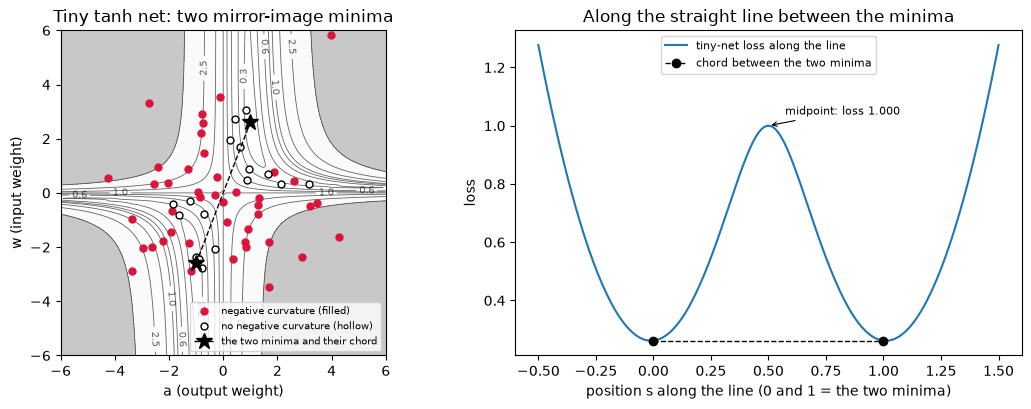

In [5]:
# the tiny network's loss over a grid of (a, w); no new random numbers are drawn here
Ag, Wg = np.meshgrid(np.linspace(-6, 6, 121), np.linspace(-6, 6, 121))
Zt = np.mean((Ag[..., None] * np.tanh(Wg[..., None] * x1) - y_pm) ** 2, axis=-1)
i_min = np.unravel_index(np.argmin(Zt), Zt.shape)
theta_min = np.array([Ag[i_min], Wg[i_min]])            # one minimum; its mirror image is -theta_min
neg = np.array(min_eig_net) < -1e-8                     # test points with a negative-curvature direction
print(f"grid minima at (a, w) = ({theta_min[0]:+.1f}, {theta_min[1]:+.1f}) and ({-theta_min[0]:+.1f}, {-theta_min[1]:+.1f}), "
      f"loss {tiny_net_loss(theta_min):.3f} at both")
print(f"loss at the midpoint (0, 0) = {tiny_net_loss(np.zeros(2)):.3f};  negative curvature at {neg.sum()} of 60 test points")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
lev = [0.3, 0.4, 0.6, 0.8, 1.0, 1.5, 2.5, 5.0]          # darker grey = higher loss
ax[0].contourf(Ag, Wg, Zt, levels=[Zt.min()] + lev + [Zt.max()], cmap="Greys", alpha=0.45)
cs = ax[0].contour(Ag, Wg, Zt, levels=lev, colors="k", linewidths=0.6, alpha=0.6)
ax[0].clabel(cs, [0.3, 0.6, 1.0, 2.5], fmt="%.1f", fontsize=7)
ax[0].plot(points[neg, 0], points[neg, 1], "o", color="crimson", ms=5, label="negative curvature (filled)")
ax[0].plot(points[~neg, 0], points[~neg, 1], "o", mfc="white", mec="k", ms=5, label="no negative curvature (hollow)")
ax[0].plot([theta_min[0], -theta_min[0]], [theta_min[1], -theta_min[1]], "k*--", ms=12, lw=1, label="the two minima and their chord")
ax[0].set_title("Tiny tanh net: two mirror-image minima"); ax[0].set_xlabel("a (output weight)"); ax[0].set_ylabel("w (input weight)")
ax[0].legend(fontsize=7, loc="lower right"); ax[0].set_aspect("equal")

s = np.linspace(-0.5, 1.5, 201)
line_pts = np.outer(1 - s, theta_min) + np.outer(s, -theta_min)  # theta(s) = (1 - s) theta_min + s (-theta_min)
ax[1].plot(s, [tiny_net_loss(p) for p in line_pts], label="tiny-net loss along the line")
ax[1].plot([0, 1], [tiny_net_loss(theta_min), tiny_net_loss(-theta_min)], "ko--", lw=1, label="chord between the two minima")
ax[1].annotate(f"midpoint: loss {tiny_net_loss(np.zeros(2)):.3f}", (0.5, tiny_net_loss(np.zeros(2))),
               textcoords="offset points", xytext=(12, 8), fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax[1].set_title("Along the straight line between the minima")
ax[1].set_xlabel("position s along the line (0 and 1 = the two minima)"); ax[1].set_ylabel("loss"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Notice that** the tiny network has two mirror-image minima, $(a, w) \approx (1.0, 2.6)$ and
$(-1.0, -2.6)$, because flipping both signs gives identical predictions ($-a\tanh(-wx) = a\tanh(wx)$,
the one-neuron version of swapping hidden units). Halfway between them the loss is $1.000$, against
$0.262$ at the ends, so the graph rises *above* the chord, which convexity forbids. The filled points,
43 of 60, have a negative Hessian eigenvalue: for this model non-convexity is the rule, not the exception.

**Try it yourself:** replace `tiny_net_loss` by the squared loss of a *linear* model
`np.mean((theta[0] + theta[1] * x1 - y_pm) ** 2)` — the smallest eigenvalue should become
non-negative everywhere.

## 3. Gradient descent on an ill-conditioned bowl

Take $L(\theta) = \tfrac12 \theta^\top A \theta$ with eigenvalues $\mu = 1$ and $L = 10$, rotated by
30° so that the axes are not aligned with the coordinates. In the eigenbasis each coordinate is
multiplied by $(1 - \eta \lambda_i)$ per step, so

* every step size $\eta < 2/L = 0.2$ converges,
* $\eta^\star = 2/(L + \mu) = 2/11 \approx 0.18$ is the fastest constant step, with rate
  $(\kappa - 1)/(\kappa + 1) = 9/11$,
* $\eta > 0.2$ makes the stiff coordinate *grow* by a factor $\lvert 1 - \eta L\rvert > 1$ per step.

Watch the four paths below: a cautious step crawls along the valley floor, a near-optimal step
zig-zags but converges, and a step just above $2/L$ zig-zags *outwards*.

eigenvalues: mu = 1.0, L = 10.0, kappa = 10.0
largest stable step 2/L = 0.200, optimal constant step 2/(L+mu) = 0.182, optimal rate (kappa-1)/(kappa+1) = 0.818
eta = 0.05: factors per step in the eigenbasis = +0.95 (flat), +0.50 (stiff);   loss after 12 steps = 9.344
eta = 0.15: factors per step in the eigenbasis = +0.85 (flat), -0.50 (stiff);   loss after 12 steps = 0.647
eta = 0.19: factors per step in the eigenbasis = +0.81 (flat), -0.90 (stiff);   loss after 12 steps = 1.799
eta = 0.21: factors per step in the eigenbasis = +0.79 (flat), -1.10 (stiff);   loss after 12 steps = 197.106


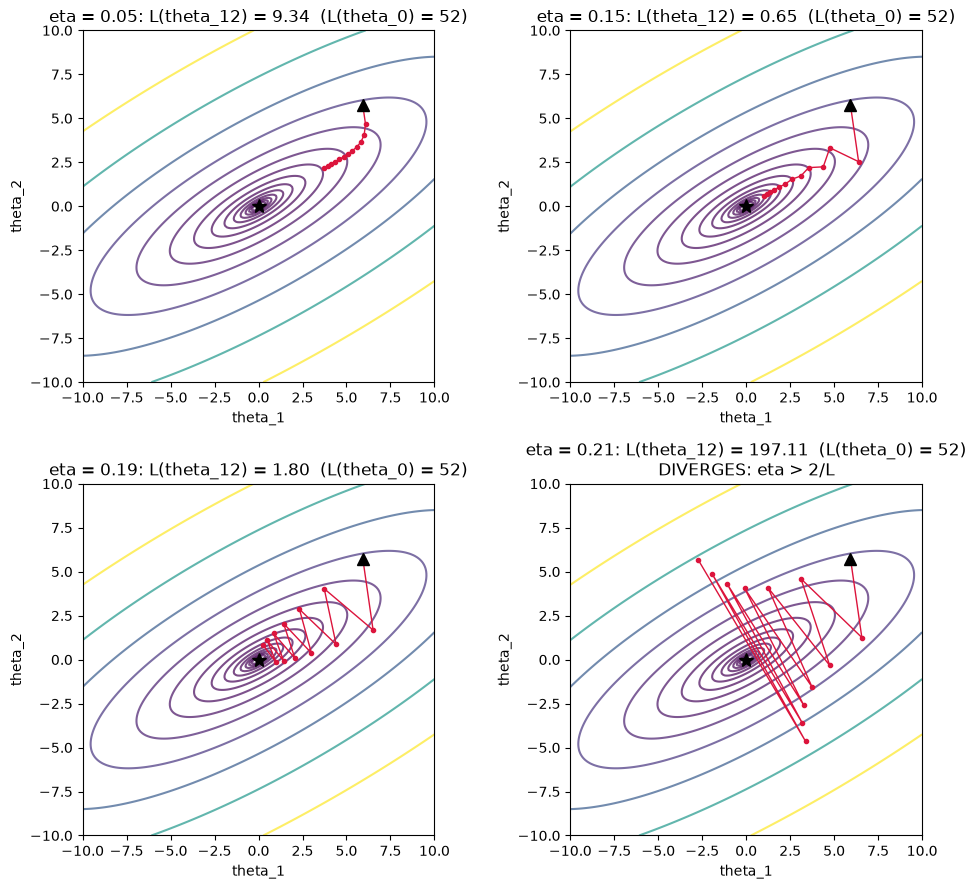

In [6]:
phi = np.deg2rad(30.0)
Q = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
A = Q @ np.diag([1.0, 10.0]) @ Q.T                      # eigenvalues 1 and 10, rotated axes
mu, L = np.linalg.eigvalsh(A)
print(f"eigenvalues: mu = {mu:.1f}, L = {L:.1f}, kappa = {L / mu:.1f}")
print(f"largest stable step 2/L = {2 / L:.3f}, optimal constant step 2/(L+mu) = {2 / (L + mu):.3f}, "
      f"optimal rate (kappa-1)/(kappa+1) = {(L - mu) / (L + mu):.3f}")

def quad_loss(th):
    return 0.5 * th @ A @ th

def gradient_descent(grad, x0, eta, steps):
    path = [np.asarray(x0, dtype=float)]
    for _ in range(steps):
        path.append(path[-1] - eta * grad(path[-1]))
    return np.array(path)

x0 = Q @ np.array([8.0, 2.0])        # 8 along the flat eigen-direction, 2 along the stiff one
G1, G2 = np.meshgrid(np.linspace(-10, 10, 201), np.linspace(-10, 10, 201))
Z = 0.5 * (A[0, 0] * G1 ** 2 + 2 * A[0, 1] * G1 * G2 + A[1, 1] * G2 ** 2)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, eta in zip(axes.ravel(), [0.05, 0.15, 0.19, 0.21]):
    path = gradient_descent(lambda th: A @ th, x0, eta, 12)
    ax.contour(G1, G2, Z, levels=np.logspace(-1, 2.6, 14), cmap="viridis", alpha=0.7)
    ax.plot(path[:, 0], path[:, 1], "o-", color="crimson", ms=3, lw=1)
    ax.plot(*x0, "k^", ms=8); ax.plot(0, 0, "k*", ms=10)
    ax.set_title(f"eta = {eta}: L(theta_12) = {quad_loss(path[-1]):.2f}  (L(theta_0) = {quad_loss(x0):.0f})"
                 + ("\nDIVERGES: eta > 2/L" if eta > 2 / L else ""))
    ax.set_xlabel("theta_1"); ax.set_ylabel("theta_2"); ax.set_aspect("equal")
    print(f"eta = {eta:.2f}: factors per step in the eigenbasis = {1 - eta * mu:+.2f} (flat), {1 - eta * L:+.2f} (stiff);"
          f"   loss after 12 steps = {quad_loss(path[-1]):.3f}")
plt.tight_layout(); plt.show()

Notice that for $\eta = 0.05$ the stiff direction is dealt with immediately but the flat direction
shrinks by only $0.95$ per step; at $\eta = 0.19$ the stiff coordinate flips sign each step (factor
$-0.9$) while the flat one shrinks by $0.81$ — the zig-zag; and at $\eta = 0.21$ the factor is
$-1.1$: the oscillation grows without bound (the loss climbs from 52 to 197 in 12 steps, even though
the flat coordinate is still shrinking — the black triangle marks the start). **No constant step size can be good for both
directions at once** — that is what the condition number measures, and it is why feature scaling,
momentum and adaptive methods exist.

### Convergence rate versus condition number

The theory predicts that GD with the optimal step needs about
$\ln(1/\varepsilon)\,/\,\ln\!\big(\tfrac{\kappa + 1}{\kappa - 1}\big) \approx \tfrac{\kappa}{2}\ln(1/\varepsilon)$
steps to shrink the error by a factor $\varepsilon$. We build random $6\times6$ quadratics with a
prescribed $\kappa$, run GD to $\varepsilon = 10^{-3}$, and measure the per-step contraction from the
last ten iterations.

kappa =    5: measured rate 0.6613 vs theory 0.6667;  steps to 1e-3:    14 (bound    17.0)
kappa =   10: measured rate 0.8182 vs theory 0.8182;  steps to 1e-3:    27 (bound    34.4)
kappa =   20: measured rate 0.9048 vs theory 0.9048;  steps to 1e-3:    66 (bound    69.0)
kappa =   50: measured rate 0.9608 vs theory 0.9608;  steps to 1e-3:   168 (bound   172.7)
kappa =  100: measured rate 0.9802 vs theory 0.9802;  steps to 1e-3:   335 (bound   345.4)
kappa =  200: measured rate 0.9900 vs theory 0.9900;  steps to 1e-3:   661 (bound   690.8)
kappa =  500: measured rate 0.9960 vs theory 0.9960;  steps to 1e-3:  1245 (bound  1726.9)


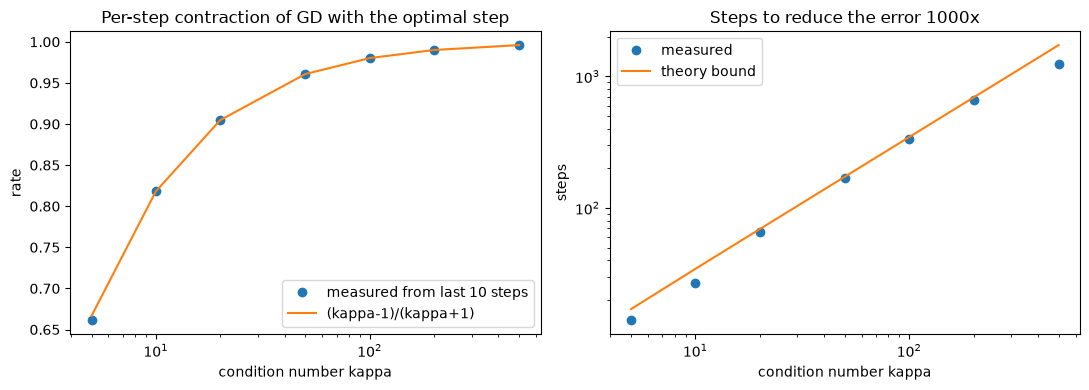

In [7]:
def random_quadratic(kappa, d=6):
    Qd, _ = np.linalg.qr(rng.normal(size=(d, d)))
    return Qd @ np.diag(np.linspace(1.0, kappa, d)) @ Qd.T

kappas = np.array([5, 10, 20, 50, 100, 200, 500])
steps_measured, rate_measured, rate_theory, steps_theory = [], [], [], []
for kappa in kappas:
    Ak = random_quadratic(kappa)
    ev = np.linalg.eigvalsh(Ak); eta = 2 / (ev[-1] + ev[0])
    th = rng.normal(size=6); tol = 1e-3 * np.linalg.norm(th); errs = []
    for k in range(20000):
        th = th - eta * (Ak @ th); errs.append(np.linalg.norm(th))
        if errs[-1] < tol:
            break
    steps_measured.append(len(errs))
    tail = min(10, len(errs) - 1)
    rate_measured.append((errs[-1] / errs[-1 - tail]) ** (1 / tail))
    rate_theory.append((kappa - 1) / (kappa + 1))
    steps_theory.append(np.log(1e-3) / np.log((kappa - 1) / (kappa + 1)))
    print(f"kappa = {kappa:4d}: measured rate {rate_measured[-1]:.4f} vs theory {rate_theory[-1]:.4f};"
          f"  steps to 1e-3: {steps_measured[-1]:5d} (bound {steps_theory[-1]:7.1f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogx(kappas, rate_measured, "o", label="measured from last 10 steps")
ax[0].semilogx(kappas, rate_theory, "-", label="(kappa-1)/(kappa+1)")
ax[0].set_title("Per-step contraction of GD with the optimal step"); ax[0].set_xlabel("condition number kappa"); ax[0].set_ylabel("rate"); ax[0].legend()
ax[1].loglog(kappas, steps_measured, "o", label="measured")
ax[1].loglog(kappas, steps_theory, "-", label="theory bound")
ax[1].set_title("Steps to reduce the error 1000x"); ax[1].set_xlabel("condition number kappa"); ax[1].set_ylabel("steps"); ax[1].legend()
plt.tight_layout(); plt.show()

Notice that the measured contraction matches $(\kappa-1)/(\kappa+1)$ to three or four decimals once
the run is long enough to settle (for $\kappa = 5$ it ends after 14 steps), and the step count grows
*linearly* in $\kappa$ (slope one on the log–log plot). The measured counts sit below the
bound (by 3 to 28%) because under $\eta^\star$ only the two extreme eigen-directions ($\mu$ and $L$)
contract at the worst-case rate, and a random start puts only part of its length along them.

### Where the condition number comes from: feature scaling

The Hessian of the mean squared error of a linear model is $\tfrac{2}{n}X^\top X$, so $\kappa$ is set
by the *scale* of the columns of $X$. Fitting a temperature trend against the raw calendar year is a
famous way to get an unusable problem.

In [8]:
years = np.arange(1980, 2021).astype(float)
for name, feature in [("raw year", years),
                      ("centred year", years - years.mean()),
                      ("standardised year", (years - years.mean()) / years.std())]:
    Xf = np.c_[np.ones_like(years), feature]
    ev = np.linalg.eigvalsh(2 * Xf.T @ Xf / len(years))
    print(f"{name:18s}: Hessian eigenvalues {ev[0]:10.3e}, {ev[1]:10.3e}   kappa = {ev[1] / ev[0]:9.3g}   2/L = {2 / ev[1]:.3g}")

raw year          : Hessian eigenvalues  7.000e-05,  8.000e+06   kappa =  1.14e+11   2/L = 2.5e-07
centred year      : Hessian eigenvalues  2.000e+00,  2.800e+02   kappa =       140   2/L = 0.00714
standardised year : Hessian eigenvalues  2.000e+00,  2.000e+00   kappa =         1   2/L = 1


Same data, same model, same optimum — but the raw parametrisation needs a step below
$2.5\times10^{-7}$ and roughly $\kappa/2 \approx 6\times10^{10}$ of them for every factor $e$ of error
reduction, while the standardised one
is solved in a single step. **Standardise your inputs** is a theorem about $\kappa$, not a
superstition.

**Try it yourself:** in the contour experiment set the eigenvalues to `[1.0, 100.0]` (so $\kappa = 100$)
and re-run with `eta = 2 / (L + mu)`. How many steps does the flat direction now need?

## 4. Stochastic gradient descent: unbiased, noisy, cheap

For linear regression on $n = 2000$ points with 5 correlated features, one full gradient costs
$2000 \times 5$ multiply-adds. A mini-batch of 8 costs $8\times5$ but is only an *estimate*:
$\mathbb{E}[g_B] = \nabla L$ (unbiased), with covariance $\tfrac{\Sigma}{b}\cdot\tfrac{n-b}{n-1} \approx \Sigma/b$. We first check both facts
directly, then compare full-batch GD with SGD at batch sizes 8, 32 and 128 using the **same number
of epochs** (passes over the data), so that every run sees the same amount of data.

In [9]:
n, d = 2000, 5
C = np.full((d, d), 0.6); np.fill_diagonal(C, 1.0)         # correlated features -> kappa ~ 9
X = rng.normal(size=(n, d)) @ np.linalg.cholesky(C).T
w_true = np.array([1.0, -2.0, 0.5, 3.0, -1.0])
y = X @ w_true + 0.5 * rng.normal(size=n)

def mse(w):
    return np.mean((X @ w - y) ** 2)

def grad_batch(w, idx):
    return 2.0 * X[idx].T @ (X[idx] @ w - y[idx]) / len(idx)

w_ols = np.linalg.lstsq(X, y, rcond=None)[0]
H = 2 * X.T @ X / n; ev = np.linalg.eigvalsh(H); L_lin = ev[-1]
print(f"Hessian eigenvalues {ev}  ->  kappa = {ev[-1] / ev[0]:.1f},  2/L = {2 / L_lin:.3f}")

# (a) unbiasedness and variance of the mini-batch gradient at a fixed point
w0 = np.zeros(d)
full_grad = grad_batch(w0, np.arange(n))
per_example = 2.0 * X * (X @ w0 - y)[:, None]                     # n x d matrix of per-example gradients
Sig = np.cov(per_example.T, bias=True)                            # population covariance Sigma of the per-example gradients
print(f"full gradient at w0 = 0: {full_grad},  norm {np.linalg.norm(full_grad):.2f}")
for b in [1, 8, 64]:
    est = np.array([grad_batch(w0, rng.choice(n, size=b, replace=False)) for _ in range(2000)])
    print(f"batch {b:3d}: mean of 2000 estimates - full gradient = {np.abs(est.mean(0) - full_grad).max():.3f} (max abs),"
          f"   trace of covariance = {np.trace(np.cov(est.T)):8.2f}   prediction tr(Sigma)/b * (n-b)/(n-1) = {np.trace(Sig) / b * (n - b) / (n - 1):8.2f}")

Hessian eigenvalues [0.7768 0.7906 0.8158 0.8446 7.0083]  ->  kappa = 9.0,  2/L = 0.285
full gradient at w0 = 0: [-2.6907 -0.2775 -2.3229 -4.1745 -1.0339],  norm 5.59
batch   1: mean of 2000 estimates - full gradient = 0.070 (max abs),   trace of covariance =   182.34   prediction tr(Sigma)/b * (n-b)/(n-1) =   187.06
batch   8: mean of 2000 estimates - full gradient = 0.125 (max abs),   trace of covariance =    22.00   prediction tr(Sigma)/b * (n-b)/(n-1) =    23.30
batch  64: mean of 2000 estimates - full gradient = 0.011 (max abs),   trace of covariance =     2.91   prediction tr(Sigma)/b * (n-b)/(n-1) =     2.83


The same facts as a picture: below, 300 fresh estimates per batch size are drawn in the plane of two
gradient coordinates, each cloud with the two-standard-deviation ellipse of the predicted covariance
(it would hold about 86% of a Gaussian cloud), and on the right the total variance is measured over a
much wider range of batch sizes. A separate random generator is used so that the rest of the lesson
sees the same random numbers as before.

batch  1: largest distance of an estimate from the full gradient =  80.7  (in the plotted plane: 43.7)
batch  8: largest distance of an estimate from the full gradient =  18.6  (in the plotted plane: 12.3)
batch 64: largest distance of an estimate from the full gradient =   4.4  (in the plotted plane:  3.2)


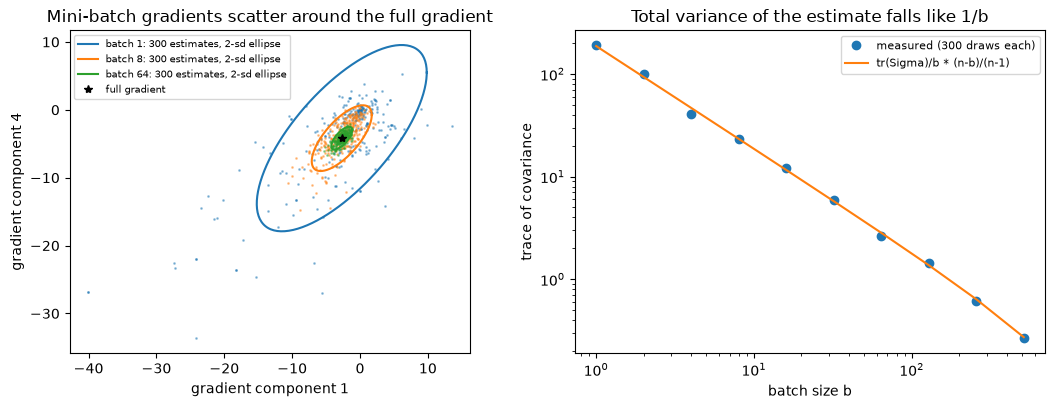

measured trace of covariance: [191.58 100.77  41.09  23.26  12.25   5.85   2.65   1.45   0.62   0.26]


In [10]:
r_cloud = np.random.default_rng(11)                      # local generator: the global rng stream is left untouched
j, k = 0, 3                                              # the two gradient coordinates to draw
tt = np.linspace(0, 2 * np.pi, 200); circle = np.c_[np.cos(tt), np.sin(tt)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for b, colour in [(1, "tab:blue"), (8, "tab:orange"), (64, "tab:green")]:
    est = np.array([grad_batch(w0, r_cloud.choice(n, size=b, replace=False)) for _ in range(300)])
    ax[0].plot(est[:, j], est[:, k], ".", color=colour, ms=2, alpha=0.4)
    C2 = Sig[np.ix_([j, k], [j, k])] / b * (n - b) / (n - 1)
    ell = full_grad[[j, k]] + 2 * circle @ np.linalg.cholesky(C2).T         # the 2-standard-deviation ellipse
    ax[0].plot(ell[:, 0], ell[:, 1], color=colour, lw=1.5, zorder=4, label=f"batch {b}: 300 estimates, 2-sd ellipse")
    print(f"batch {b:2d}: largest distance of an estimate from the full gradient = {np.linalg.norm(est - full_grad, axis=1).max():5.1f}"
          f"  (in the plotted plane: {np.linalg.norm(est[:, [j, k]] - full_grad[[j, k]], axis=1).max():4.1f})")
ax[0].plot(*full_grad[[j, k]], "k*", ms=6, zorder=5, label="full gradient")
ax[0].set_title("Mini-batch gradients scatter around the full gradient")
ax[0].set_xlabel(f"gradient component {j + 1}"); ax[0].set_ylabel(f"gradient component {k + 1}")
ax[0].legend(fontsize=7, loc="upper left"); ax[0].set_aspect("equal")

bs = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512])
tr_meas = [np.trace(np.cov(np.array([grad_batch(w0, r_cloud.choice(n, size=b, replace=False)) for _ in range(300)]).T)) for b in bs]
ax[1].loglog(bs, tr_meas, "o", label="measured (300 draws each)")
ax[1].loglog(bs, np.trace(Sig) / bs * (n - bs) / (n - 1), "-", label="tr(Sigma)/b * (n-b)/(n-1)")
ax[1].set_title("Total variance of the estimate falls like 1/b")
ax[1].set_xlabel("batch size b"); ax[1].set_ylabel("trace of covariance"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("measured trace of covariance:", np.round(tr_meas, 2))

**Notice that** every cloud is centred on the star (the estimate is unbiased) and each ellipse is
$\sqrt8 \approx 2.8$ times smaller than the previous one. The printed means agree with the full
gradient (norm 5.6) to within the Monte-Carlo error of 2000 draws: the largest deviations, 0.07, 0.12
and 0.01, are about two standard errors or less. On the right the measured variance follows
$\operatorname{tr}\Sigma/b\cdot(n-b)/(n-1)$ over nearly three decades of $b$. The batch-1 cloud is also
heavy-tailed: single-example gradients land up to about 44 units from the star in this plane, and up
to 81 units away in all five coordinates, against a full gradient of norm 5.6 — which is why
per-example SGD needs small steps.

Now the training runs. We use $\eta = 1/L$ for every batch size; each run gets 20 epochs.

batch     8 ( 250 steps/epoch): excess loss after epoch 1 = 0.0149,   mean excess over last epoch = 5.24e-02
batch    32 (  62 steps/epoch): excess loss after epoch 1 = 0.0064,   mean excess over last epoch = 8.35e-03
batch   128 (  15 steps/epoch): excess loss after epoch 1 = 0.1679,   mean excess over last epoch = 1.82e-03
batch  2000 (   1 steps/epoch): excess loss after epoch 1 = 4.6005,   mean excess over last epoch = 5.15e-02


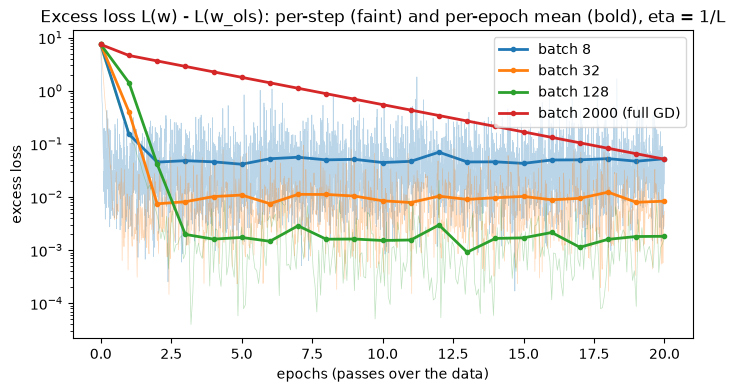

In [11]:
def sgd(batch_size, eta, epochs, seed, schedule=None):
    r = np.random.default_rng(seed)
    w = np.zeros(d); hist = []; t = 0
    steps_per_epoch = n // batch_size
    for _ in range(epochs):
        perm = r.permutation(n)
        for s in range(steps_per_epoch):
            idx = perm[s * batch_size:(s + 1) * batch_size]
            lr = eta if schedule is None else schedule(t)
            w = w - lr * grad_batch(w, idx); t += 1
            hist.append(mse(w))
    return w, np.array(hist)

epochs, eta = 20, 1 / L_lin
runs = {}
for b in [8, 32, 128, n]:
    w_b, hist = runs[b] = sgd(b, eta, epochs, seed=1)
    spe = n // b
    print(f"batch {b:5d} ({spe:4d} steps/epoch): excess loss after epoch 1 = {hist[spe - 1] - mse(w_ols):.4f},"
          f"   mean excess over last epoch = {hist[-spe:].mean() - mse(w_ols):.2e}")

excess0 = mse(np.zeros(d)) - mse(w_ols)                 # common starting point at epoch 0
plt.figure(figsize=(8, 4))
for i_run, (b, (w_b, hist)) in enumerate(runs.items()):
    spe = n // b
    ep = np.arange(0, len(hist) + 1) / spe
    plt.semilogy(ep, np.r_[excess0, hist - mse(w_ols)], color=f"C{i_run}", lw=0.5, alpha=0.3)
    epoch_means = np.r_[excess0, hist.reshape(epochs, spe).mean(1) - mse(w_ols)]   # mean excess over each epoch
    plt.semilogy(np.arange(epochs + 1), epoch_means, "o-", color=f"C{i_run}", ms=3, lw=2,
                 label=f"batch {b}" + (" (full GD)" if b == n else ""))
plt.title("Excess loss L(w) - L(w_ols): per-step (faint) and per-epoch mean (bold), eta = 1/L")
plt.xlabel("epochs (passes over the data)"); plt.ylabel("excess loss"); plt.legend(loc="upper right"); plt.show()

Notice three things. (1) Per epoch, SGD wins by a landslide: full GD takes one step per pass and
after 20 passes is only where batch-8 SGD was after a fraction of *one* pass. (By epoch 20 full GD has
caught up with batch 8's noise floor, about $5\times10^{-2}$; batches 32 and 128 end about 6 and 28 times
lower.) (2) Smaller batches
plateau at a *higher noise floor*: the bold per-epoch means level off at about $5\times10^{-2}$
(batch 8), $8\times10^{-3}$ (batch 32) and $2\times10^{-3}$ (batch 128), because with a constant step
the iterates hover in a "noise ball" whose variance is $\propto \eta\sigma^2/b$. (3) Batch 128 is the
sweet spot here — low noise, 15 steps per epoch.

The cure for the noise floor is a **decaying step size**. Below we re-run batch 8 with a
$1/t$-type decay and a cosine schedule, and also verify the noise-ball formula
$\mathrm{Var}(\theta_\infty) = \eta\sigma^2/(\lambda(2 - \eta\lambda))$ on a 1-D quadratic with artificial
gradient noise.

batch 8, constant     : excess loss at the last step = 1.76e-02,   mean excess over the last epoch = 5.24e-02
batch 8, 1/t decay    : excess loss at the last step = 1.94e-04,   mean excess over the last epoch = 5.10e-04
batch 8, cosine decay : excess loss at the last step = 6.89e-05,   mean excess over the last epoch = 7.71e-05


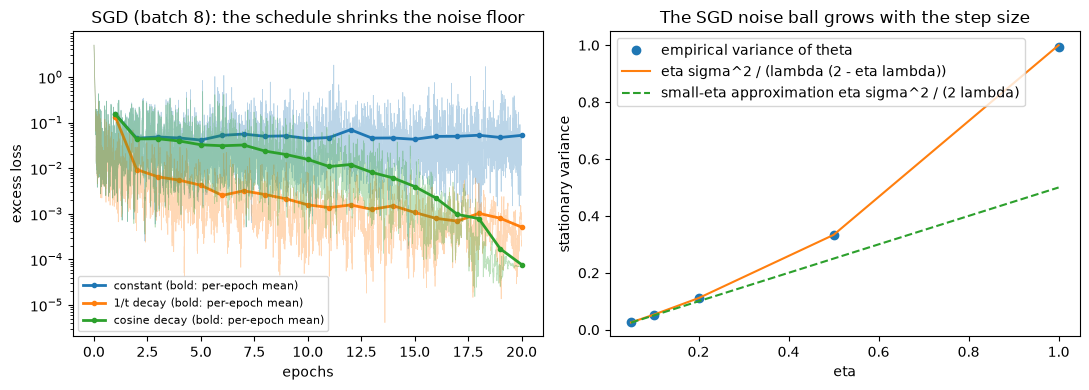

In [12]:
spe = n // 8
_, hist_const = runs[8]
_, hist_inv = sgd(8, eta, epochs, seed=1, schedule=lambda t: eta / (1 + t / spe))
_, hist_cos = sgd(8, eta, epochs, seed=1, schedule=lambda t: eta * 0.5 * (1 + np.cos(np.pi * t / (epochs * spe))))
for name, h in [("constant", hist_const), ("1/t decay", hist_inv), ("cosine decay", hist_cos)]:
    print(f"batch 8, {name:13s}: excess loss at the last step = {h[-1] - mse(w_ols):.2e},"
          f"   mean excess over the last epoch = {h[-spe:].mean() - mse(w_ols):.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(hist_const) + 1) / spe
for i_run, (name, h) in enumerate([("constant", hist_const), ("1/t decay", hist_inv), ("cosine decay", hist_cos)]):
    ax[0].semilogy(ep, h - mse(w_ols), color=f"C{i_run}", lw=0.5, alpha=0.3)
    ax[0].semilogy(np.arange(1, epochs + 1), h.reshape(epochs, spe).mean(1) - mse(w_ols), "o-", color=f"C{i_run}",
                   ms=3, lw=2, label=f"{name} (bold: per-epoch mean)")
ax[0].set_title("SGD (batch 8): the schedule shrinks the noise floor"); ax[0].set_xlabel("epochs"); ax[0].set_ylabel("excess loss"); ax[0].legend(fontsize=8)

# noise-ball check on L(theta) = lambda/2 theta^2 with gradient noise of variance sigma^2
lam, sigma = 1.0, 1.0
etas = np.array([0.05, 0.1, 0.2, 0.5, 1.0]); emp = []
for e in etas:
    th = 0.0; r = np.random.default_rng(3); samples = []
    for t in range(20000):
        th = th - e * (lam * th + sigma * r.normal())
        if t > 2000:
            samples.append(th)
    emp.append(np.var(samples))
ax[1].plot(etas, emp, "o", label="empirical variance of theta")
ax[1].plot(etas, etas * sigma ** 2 / (lam * (2 - etas * lam)), "-", label="eta sigma^2 / (lambda (2 - eta lambda))")
ax[1].plot(etas, etas * sigma ** 2 / (2 * lam), "--", label="small-eta approximation eta sigma^2 / (2 lambda)")
ax[1].set_title("The SGD noise ball grows with the step size"); ax[1].set_xlabel("eta"); ax[1].set_ylabel("stationary variance"); ax[1].legend()
plt.tight_layout(); plt.show()

Notice that the noise-ball formula is exact (the dots sit on the solid curve), and that cosine decay
brings batch-8 SGD to below $10^{-4}$ of the optimum (a last-epoch mean of $7.7\times10^{-5}$, against
$5.1\times10^{-4}$ for the $1/t$ decay and $5.2\times10^{-2}$ for the constant step — nearly three orders
of magnitude better) using exactly the same gradients. Large-model training recipes (warm-up, then cosine
decay to 10% of the peak) are this experiment at scale.

**Try it yourself:** change the batch-8 constant step to `eta / 4`. The noise floor drops by about
4x, but how many more epochs does the first phase take?

## 5. Momentum, RMSProp and Adam from their update equations

All five optimisers below are a few lines each. We write them as functions of the gradient
$g_t$ with an explicit state so that the equations are visible:

| method | state update | step |
|---|---|---|
| GD | – | $\theta \leftarrow \theta - \eta g$ |
| heavy ball | $v \leftarrow \beta v + g$ | $\theta \leftarrow \theta - \eta v$ |
| Nesterov | $v \leftarrow \beta v + \nabla L(\theta - \eta\beta v)$ | $\theta \leftarrow \theta - \eta v$ |
| RMSProp | $s \leftarrow \rho s + (1-\rho) g^2$ | $\theta \leftarrow \theta - \eta\, g / (\sqrt{s} + \epsilon)$ |
| Adam | $m \leftarrow \beta_1 m + (1-\beta_1) g$, $v \leftarrow \beta_2 v + (1-\beta_2) g^2$ | $\theta \leftarrow \theta - \eta\, \hat m / (\sqrt{\hat v} + \epsilon)$ with $\hat m = m/(1-\beta_1^t)$, $\hat v = v/(1-\beta_2^t)$ |

The test function is Rosenbrock's banana $f(x, y) = (1 - x)^2 + 100 (y - x^2)^2$: a curved, narrow
valley whose floor has very low curvature along the valley and very high curvature across it — the
ill-conditioned bowl of Section 3, bent.

gd        eta = 0.002: f after 500 steps =  3.85e-01,  after 2000 =  8.78e-03,  final point = [0.9064 0.8211]
momentum  eta = 0.002: f after 500 steps =  3.29e-05,  after 2000 =  1.45e-16,  final point = [1. 1.]
nesterov  eta = 0.001: f after 500 steps =  1.68e-03,  after 2000 =  5.88e-09,  final point = [0.9999 0.9998]
rmsprop   eta =  0.01: f after 500 steps =  2.33e-01,  after 2000 =  2.37e-02,  final point = [0.9511 0.89  ]
adam      eta =   0.1: f after 500 steps =  2.18e-01,  after 2000 =  2.30e-09,  final point = [1.     0.9999]


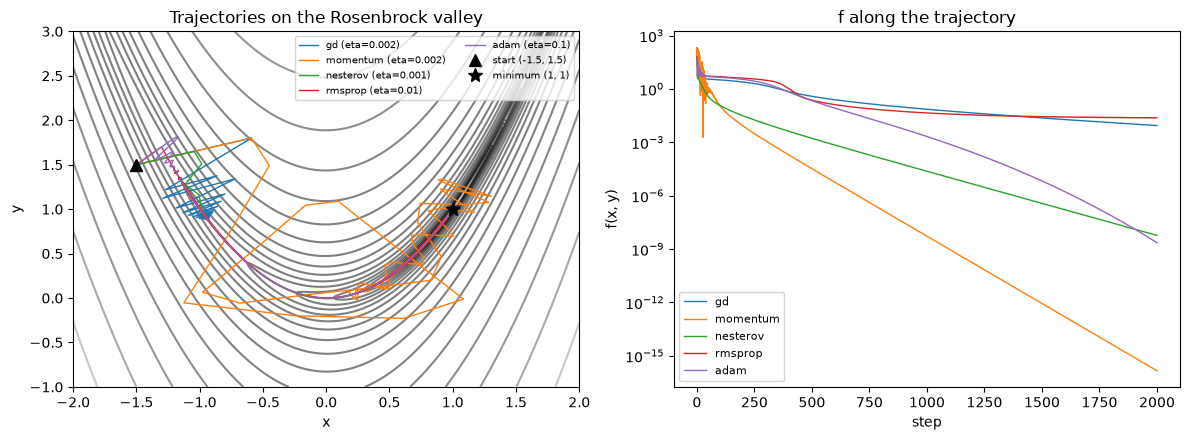

In [13]:
def rosenbrock(p):
    x, y = p
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

def rosenbrock_grad(p):
    x, y = p
    return np.array([-2 * (1 - x) - 400 * x * (y - x ** 2), 200 * (y - x ** 2)])

def optimise(grad, x0, method, eta, steps, beta=0.9, rho=0.9, beta1=0.9, beta2=0.999, eps=1e-8):
    theta = np.asarray(x0, dtype=float)
    v = np.zeros_like(theta); s = np.zeros_like(theta); m = np.zeros_like(theta)
    path = [theta.copy()]
    for t in range(1, steps + 1):
        if method == "gd":
            theta = theta - eta * grad(theta)
        elif method == "momentum":
            v = beta * v + grad(theta)
            theta = theta - eta * v
        elif method == "nesterov":
            v = beta * v + grad(theta - eta * beta * v)
            theta = theta - eta * v
        elif method == "rmsprop":
            g = grad(theta); s = rho * s + (1 - rho) * g * g
            theta = theta - eta * g / (np.sqrt(s) + eps)
        elif method == "adam":
            g = grad(theta)
            m = beta1 * m + (1 - beta1) * g
            v = beta2 * v + (1 - beta2) * g * g
            m_hat = m / (1 - beta1 ** t); v_hat = v / (1 - beta2 ** t)
            theta = theta - eta * m_hat / (np.sqrt(v_hat) + eps)
        path.append(theta.copy())
    return np.array(path)

x0 = (-1.5, 1.5)
settings = {"gd": 2e-3, "momentum": 2e-3, "nesterov": 1e-3, "rmsprop": 1e-2, "adam": 1e-1}
paths = {mth: optimise(rosenbrock_grad, x0, mth, eta, 2000) for mth, eta in settings.items()}

G1, G2 = np.meshgrid(np.linspace(-2, 2, 301), np.linspace(-1, 3, 301))
Z = (1 - G1) ** 2 + 100 * (G2 - G1 ** 2) ** 2
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].contour(G1, G2, Z, levels=np.logspace(-1, 3.5, 20), cmap="gray", alpha=0.5)
for mth, path in paths.items():
    ax[0].plot(path[:, 0], path[:, 1], lw=1, label=f"{mth} (eta={settings[mth]:g})")
    fvals = np.array([rosenbrock(p) for p in path])
    ax[1].semilogy(fvals, lw=1, label=mth)
    print(f"{mth:9s} eta = {settings[mth]:5g}: f after 500 steps = {fvals[500]:9.2e},  after 2000 = {fvals[-1]:9.2e},  final point = {path[-1]}")
ax[0].plot(*x0, "k^", ms=8, label="start (-1.5, 1.5)"); ax[0].plot(1, 1, "k*", ms=10, label="minimum (1, 1)")
ax[0].set_title("Trajectories on the Rosenbrock valley"); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[0].legend(fontsize=7, loc="upper right", ncol=2)          # the band y > 2 holds no trajectory
ax[1].set_title("f along the trajectory"); ax[1].set_xlabel("step"); ax[1].set_ylabel("f(x, y)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Notice how plain GD creeps along the valley floor: its step is limited by the *across-valley*
curvature ($\approx 2/L$) and the *along-valley* progress per step is tiny. Momentum accumulates
along-valley velocity (effective step $\eta/(1-\beta) = 10\eta$) and reaches $10^{-16}$. Adam and
RMSProp normalise each coordinate by its own gradient scale, so they take steps of size $\approx\eta$
regardless of the curvature; Adam with $\eta = 0.1$ is fast here, with $\eta = 0.01$ it would be the
slowest of all — the learning rate still matters.

**Try it yourself:** set `momentum` to `eta = 3e-3`. It diverges within a handful of steps — the
stability limit of heavy ball is about $2(1+\beta)/L$, roughly twice GD's $2/L$. Momentum buys speed
along the valley, not a much larger stable step.

### Bias correction, and why Adam's first steps have size ≈ η

Adam's running averages start at zero, so for small $t$ the raw $m_t$ and $v_t$ are biased towards
zero — but not by the same factor. Without correction the first step would be
$\eta\,(1-\beta_1) g / \sqrt{(1-\beta_2) g^2} = \eta \cdot 0.1/\sqrt{0.001} \approx 3.16\,\eta$. With correction it is
exactly $\eta\,\mathrm{sign}(g)$ (ignoring $\epsilon$), whatever the magnitude of $g$.

g = [   0.1 -100. ]:  step/eta without bias correction = [ 3.1623 -3.1623],  with correction = [ 1. -1.]
g = [    0.0001 10000.    ]:  step/eta without bias correction = [3.1623 3.1623],  with correction = [1. 1.]


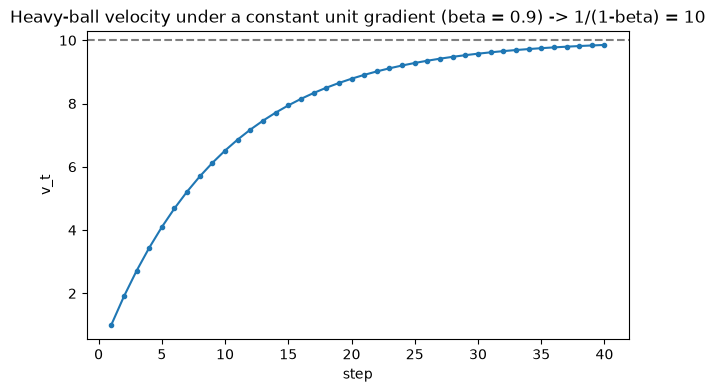

In [14]:
beta1, beta2 = 0.9, 0.999
for g in [np.array([0.1, -100.0]), np.array([1e-4, 1e4])]:
    m1 = (1 - beta1) * g; v1 = (1 - beta2) * g * g
    print(f"g = {g}:  step/eta without bias correction = {m1 / np.sqrt(v1)},  with correction = {(m1 / (1 - beta1)) / np.sqrt(v1 / (1 - beta2))}")

# heavy-ball velocity under a constant gradient converges to g/(1-beta)
v = 0.0; vs = []
for t in range(40):
    v = 0.9 * v + 1.0; vs.append(v)
plt.plot(range(1, 41), vs, "o-", ms=3); plt.axhline(10, color="gray", ls="--")
plt.title("Heavy-ball velocity under a constant unit gradient (beta = 0.9) -> 1/(1-beta) = 10")
plt.xlabel("step"); plt.ylabel("v_t"); plt.show()

The printout covers only step 1. Below we follow $\lvert\text{step}\rvert/\eta$ for 3000 steps, with
and without the bias correction, once for a constant gradient $g = 0.1$ and once for a noisy gradient
whose mean is still $0.1$ but whose standard deviation is $0.3$.

constant gradient, no correction: step 1 = 3.16 eta, peak 6.57 eta at t = 12, t = 100: 3.24 eta, t = 1000: 1.26 eta;  with correction: between 1.0000 and 1.0000 eta
noisy gradient, with correction: mean |step|/eta over the last 1000 steps = 0.33   (|mean g| / rms(g) = 0.32)


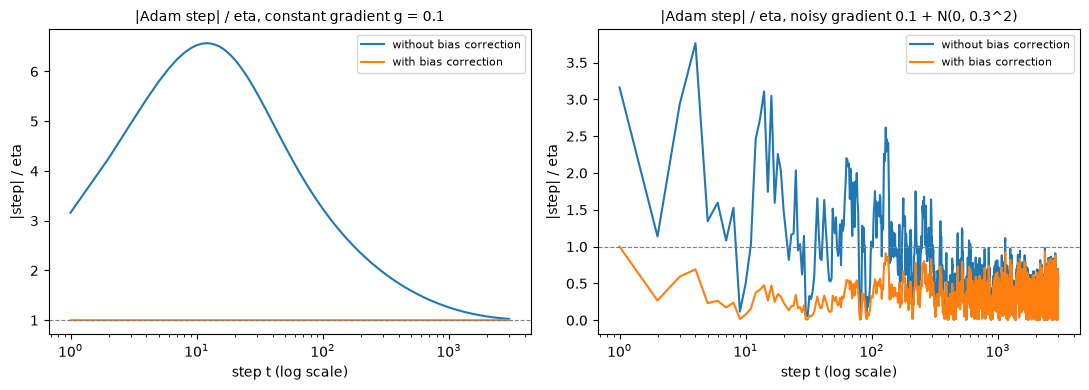

In [15]:
t_ad = np.arange(1, 3001)
r_ad = np.random.default_rng(4)                          # local generator for the noisy gradient
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i_ax, (label, gs) in enumerate([("constant gradient g = 0.1", np.full(len(t_ad), 0.1)),
                                    ("noisy gradient 0.1 + N(0, 0.3^2)", 0.1 + 0.3 * r_ad.normal(size=len(t_ad)))]):
    m_a = v_a = 0.0; raw, corr = [], []
    for t_k, g_k in zip(t_ad, gs):
        m_a = beta1 * m_a + (1 - beta1) * g_k; v_a = beta2 * v_a + (1 - beta2) * g_k * g_k
        raw.append(abs(m_a) / np.sqrt(v_a))
        corr.append(abs(m_a / (1 - beta1 ** t_k)) / np.sqrt(v_a / (1 - beta2 ** t_k)))
    ax[i_ax].semilogx(t_ad, raw, label="without bias correction")
    ax[i_ax].semilogx(t_ad, corr, label="with bias correction")
    ax[i_ax].axhline(1, color="gray", ls="--", lw=0.8)
    ax[i_ax].set_title(f"|Adam step| / eta, {label}", fontsize=10)
    ax[i_ax].set_xlabel("step t (log scale)"); ax[i_ax].set_ylabel("|step| / eta"); ax[i_ax].legend(fontsize=8)
    if i_ax == 0:
        raw = np.array(raw)
        print(f"constant gradient, no correction: step 1 = {raw[0]:.2f} eta, peak {raw.max():.2f} eta at t = {int(np.argmax(raw)) + 1},"
              f" t = 100: {raw[99]:.2f} eta, t = 1000: {raw[999]:.2f} eta;  with correction: between {min(corr):.4f} and {max(corr):.4f} eta")
    else:
        print(f"noisy gradient, with correction: mean |step|/eta over the last 1000 steps = {np.mean(corr[-1000:]):.2f}"
              f"   (|mean g| / rms(g) = {abs(gs.mean()) / np.sqrt(np.mean(gs ** 2)):.2f})")
plt.tight_layout(); plt.show()

**Notice that** without bias correction the first step is $3.16\eta$ and the steps keep *growing*, to
about $6.6\eta$ at $t = 12$, and are still $3.2\eta$ at $t = 100$ — an anti-warm-up exactly when the
iterate is least trustworthy. With the correction the step is exactly $\eta$ for a consistent gradient.
Under noise (right) even the corrected step is only about $\eta\,\lvert\text{mean } g\rvert/\text{rms}(g)
\approx 0.3\eta$: Adam slows down by itself when the gradient direction is unreliable.

### Why momentum helps: the rotated bowl again, with κ = 100

The velocity plot above showed that under a *constant* gradient the heavy-ball velocity builds up to
$g/(1-\beta)$. On the bowl of Section 3, made harder with eigenvalues $1$ and $100$, we now compare GD at
its optimal step $2/(L+\mu)$, the default heavy ball ($\beta = 0.9$, $\eta = 1/L$) and the tuned heavy
ball ($\beta = \big(\tfrac{\sqrt\kappa-1}{\sqrt\kappa+1}\big)^2 = (9/11)^2$, $\eta = \big(\tfrac{2}{\sqrt L+\sqrt\mu}\big)^2$),
and look at the default heavy ball's velocity in the eigenbasis.

GD, eta = 2/(L+mu)              : ||theta_60|| = 2.48e+00,  ||theta_120|| = 7.48e-01
heavy ball, beta = 0.9          : ||theta_60|| = 6.88e-02,  ||theta_120|| = 1.32e-02
tuned heavy ball, beta = 0.669  : ||theta_60|| = 1.42e-03,  ||theta_120|| = 1.65e-08
flat component:  gradient never exceeds 8.0, velocity peaks at 44.4 (step 12)
stiff component: gradient peaks at 200, velocity peaks at 200


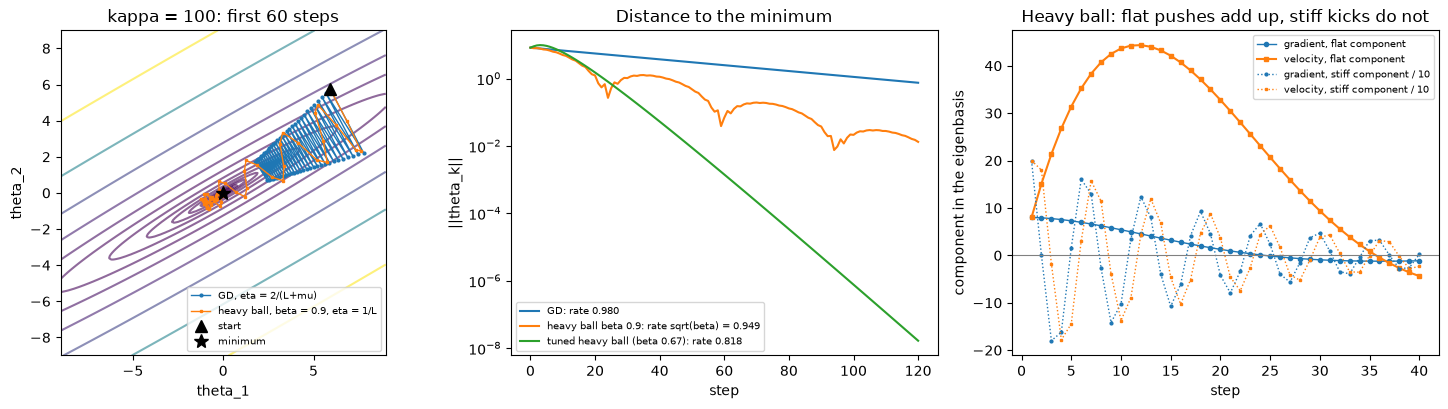

In [16]:
A100 = Q @ np.diag([1.0, 100.0]) @ Q.T                    # same rotation as Section 3, kappa = 100
mu_b, L_b = 1.0, 100.0
th0 = Q @ np.array([8.0, 2.0]); steps_m = 120
beta_t = ((np.sqrt(L_b) - np.sqrt(mu_b)) / (np.sqrt(L_b) + np.sqrt(mu_b))) ** 2
eta_t = (2 / (np.sqrt(L_b) + np.sqrt(mu_b))) ** 2
gd_p = optimise(lambda th: A100 @ th, th0, "gd", 2 / (L_b + mu_b), steps_m)
hb_p = optimise(lambda th: A100 @ th, th0, "momentum", 1 / L_b, steps_m, beta=0.9)
hbt_p = optimise(lambda th: A100 @ th, th0, "momentum", eta_t, steps_m, beta=beta_t)

# the heavy ball's velocity v_t = beta v_(t-1) + g_t, recomputed from its path and rotated into the eigenbasis (flat, stiff)
v_hb = np.zeros(2); v_eig, g_eig = [], []
for th in hb_p[:-1]:
    g_hb = A100 @ th; v_hb = 0.9 * v_hb + g_hb
    v_eig.append(Q.T @ v_hb); g_eig.append(Q.T @ g_hb)
v_eig, g_eig = np.array(v_eig), np.array(g_eig)
for name, pth in [("GD, eta = 2/(L+mu)", gd_p), ("heavy ball, beta = 0.9", hb_p), (f"tuned heavy ball, beta = {beta_t:.3f}", hbt_p)]:
    print(f"{name:32s}: ||theta_60|| = {np.linalg.norm(pth[60]):.2e},  ||theta_120|| = {np.linalg.norm(pth[120]):.2e}")
print(f"flat component:  gradient never exceeds {np.abs(g_eig[:, 0]).max():.1f}, velocity peaks at {v_eig[:, 0].max():.1f} (step {int(np.argmax(v_eig[:, 0])) + 1})")
print(f"stiff component: gradient peaks at {np.abs(g_eig[:, 1]).max():.0f}, velocity peaks at {np.abs(v_eig[:, 1]).max():.0f}")

Gx, Gy = np.meshgrid(np.linspace(-9, 9, 181), np.linspace(-9, 9, 181))
Zb = 0.5 * (A100[0, 0] * Gx ** 2 + 2 * A100[0, 1] * Gx * Gy + A100[1, 1] * Gy ** 2)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].contour(Gx, Gy, Zb, levels=np.logspace(-1, 3.5, 14), cmap="viridis", alpha=0.6)
ax[0].plot(gd_p[:61, 0], gd_p[:61, 1], "o-", ms=2, lw=1, label="GD, eta = 2/(L+mu)")
ax[0].plot(hb_p[:61, 0], hb_p[:61, 1], "s-", ms=2, lw=1, label="heavy ball, beta = 0.9, eta = 1/L")
ax[0].plot(*th0, "k^", ms=8, label="start"); ax[0].plot(0, 0, "k*", ms=10, label="minimum")
ax[0].set_title("kappa = 100: first 60 steps"); ax[0].set_xlabel("theta_1"); ax[0].set_ylabel("theta_2")
ax[0].legend(fontsize=7, loc="lower right"); ax[0].set_aspect("equal")
k_m = np.arange(steps_m + 1)
ax[1].semilogy(k_m, np.linalg.norm(gd_p, axis=1), label="GD: rate 0.980")
ax[1].semilogy(k_m, np.linalg.norm(hb_p, axis=1), label="heavy ball beta 0.9: rate sqrt(beta) = 0.949")
ax[1].semilogy(k_m, np.linalg.norm(hbt_p, axis=1), label=f"tuned heavy ball (beta {beta_t:.2f}): rate 0.818")
ax[1].set_title("Distance to the minimum"); ax[1].set_xlabel("step"); ax[1].set_ylabel("||theta_k||"); ax[1].legend(fontsize=7)
t_m = np.arange(1, 41)
ax[2].plot(t_m, g_eig[:40, 0], "o-", ms=3, lw=1, color="tab:blue", label="gradient, flat component")
ax[2].plot(t_m, v_eig[:40, 0], "s-", ms=3, lw=1.5, color="tab:orange", label="velocity, flat component")
ax[2].plot(t_m, g_eig[:40, 1] / 10, "o:", ms=2, lw=1, color="tab:blue", label="gradient, stiff component / 10")
ax[2].plot(t_m, v_eig[:40, 1] / 10, "s:", ms=2, lw=1, color="tab:orange", label="velocity, stiff component / 10")
ax[2].axhline(0, color="gray", lw=0.8)
ax[2].set_title("Heavy ball: flat pushes add up, stiff kicks do not"); ax[2].set_xlabel("step")
ax[2].set_ylabel("component in the eigenbasis"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Notice that** after 60 steps GD has only reached $\lVert\theta\rVert = 2.5$, the default heavy ball
($\beta = 0.9$, $\eta = 1/L$) $0.07$ and the tuned heavy ball $1.4\times10^{-3}$. In the middle panel GD
falls along a straight line with slope $0.980$ per step; the default heavy ball oscillates under an
envelope that shrinks by $\sqrt\beta = 0.949$ per step (step 60 happens to fall in one of its dips:
between steps 50 and 70 it ranges from 0.04 to 0.48); and the tuned heavy ball falls at $0.818$ per step,
times the slowly growing factor $k$ of its critically damped modes. The right panel shows why: along the flat direction successive gradients
share a sign, so the velocity piles up to 44, more than five times the largest flat gradient (8.0); along the stiff
direction the gradient keeps changing sign and the velocity never exceeds a single gradient (both
peak at 200). Momentum is a large step along the valley and a small one across it — the $\sqrt\kappa$
instead of $\kappa$ of the guide.

### The same optimisers on a real problem: logistic regression

The breast-cancer data (569 tumours, 30 features) with standardised features and a small ridge
term $\lambda = 10^{-2}$. The loss is convex, so every method converges to the *same* optimum; what
differs is how fast. We log the loss for 300 full-batch steps of each method.

Hessian at w = 0 (standardised): L = 3.330, mu = 1.00e-02, kappa = 332, 2/L = 0.601
Hessian at w = 0 (raw features) : L = 4.16e+05,  2/L = 4.80e-06   <- why unscaled GD seems 'broken'
optimum: L(w*) = 0.0995913755;  Hessian at w*: L = 0.222, mu = 9.71e-03, kappa = 22.9
gd        eta =   0.5: loss at step 50 = 0.1039, 150 = 0.1000;  excess at step 300 = 2.7e-05;  train accuracy = 0.9859
momentum  eta =   0.3: loss at step 50 = 0.1011, 150 = 0.0996;  excess at step 300 = 1.7e-14;  train accuracy = 0.9859
nesterov  eta =   0.3: loss at step 50 = 0.1000, 150 = 0.0996;  excess at step 300 = 2.8e-16;  train accuracy = 0.9859
rmsprop   eta =  0.01: loss at step 50 = 0.1164, 150 = 0.0996;  excess at step 300 = 8.0e-05;  train accuracy = 0.9859
adam      eta =  0.05: loss at step 50 = 0.1032, 150 = 0.0996;  excess at step 300 = 4.3e-09;  train accuracy = 0.9859


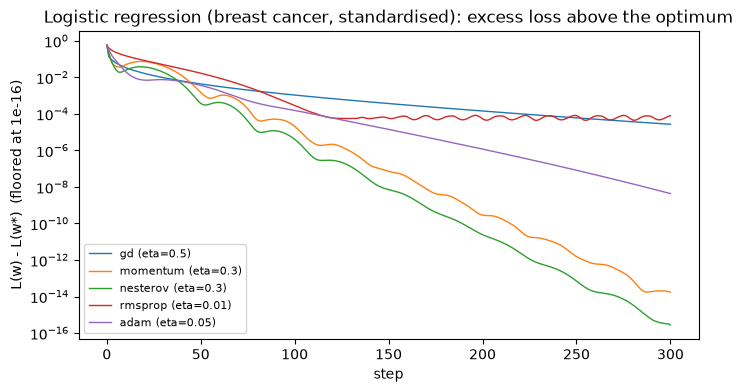

In [17]:
data = load_breast_cancer()
X_raw, y_bc = data.data, data.target.astype(float)
X_std = (X_raw - X_raw.mean(0)) / X_raw.std(0)
Xb = np.c_[np.ones(len(X_std)), X_std]                 # 569 x 31 with an intercept column
lam_ridge = 1e-2

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(w, X=Xb, y=y_bc):
    z = X @ w
    return np.mean(y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z)) + 0.5 * lam_ridge * (w[1:] @ w[1:])

def log_grad(w, X=Xb, y=y_bc):
    g = X.T @ (sigmoid(X @ w) - y) / len(y)
    g[1:] += lam_ridge * w[1:]
    return g

def log_hess(w, X=Xb, y=y_bc):
    p = sigmoid(X @ w); s = p * (1 - p)
    Hm = (X * s[:, None]).T @ X / len(y)
    Hm[1:, 1:] += lam_ridge * np.eye(X.shape[1] - 1)
    return Hm

ev0 = np.linalg.eigvalsh(log_hess(np.zeros(Xb.shape[1])))
print(f"Hessian at w = 0 (standardised): L = {ev0[-1]:.3f}, mu = {ev0[0]:.2e}, kappa = {ev0[-1] / ev0[0]:.3g}, 2/L = {2 / ev0[-1]:.3f}")
ev_raw = np.linalg.eigvalsh(0.25 * np.c_[np.ones(len(X_raw)), X_raw].T @ np.c_[np.ones(len(X_raw)), X_raw] / len(X_raw))
print(f"Hessian at w = 0 (raw features) : L = {ev_raw[-1]:.3g},  2/L = {2 / ev_raw[-1]:.2e}   <- why unscaled GD seems 'broken'")

# the optimum L(w*) itself, from 10 Newton steps (Section 6 explains why this converges so fast)
w_opt = np.zeros(Xb.shape[1])
for _ in range(10):
    w_opt = w_opt - np.linalg.solve(log_hess(w_opt), log_grad(w_opt))
L_star = log_loss(w_opt)
ev_opt = np.linalg.eigvalsh(log_hess(w_opt))
print(f"optimum: L(w*) = {L_star:.10f};  Hessian at w*: L = {ev_opt[-1]:.3f}, mu = {ev_opt[0]:.2e}, kappa = {ev_opt[-1] / ev_opt[0]:.3g}")

lr_settings = {"gd": 0.5, "momentum": 0.3, "nesterov": 0.3, "rmsprop": 0.01, "adam": 0.05}
w0 = np.zeros(Xb.shape[1])
plt.figure(figsize=(8, 4))
for mth, eta in lr_settings.items():
    path = optimise(log_grad, w0, mth, eta, 300)
    losses = np.array([log_loss(w) for w in path])
    acc = np.mean((Xb @ path[-1] > 0) == (y_bc == 1))
    print(f"{mth:9s} eta = {eta:5g}: loss at step 50 = {losses[50]:.4f}, 150 = {losses[150]:.4f};  excess at step 300 = {losses[300] - L_star:.1e};  train accuracy = {acc:.4f}")
    plt.semilogy(np.maximum(losses - L_star, 1e-16), lw=1, label=f"{mth} (eta={eta:g})")
plt.title("Logistic regression (breast cancer, standardised): excess loss above the optimum")
plt.xlabel("step"); plt.ylabel("L(w) - L(w*)  (floored at 1e-16)"); plt.legend(fontsize=8); plt.show()

Notice that the condition number at $w = 0$ is still $\approx 330$ after standardisation — and it is
set by the ridge term: without it $\mu \approx 3\times10^{-5}$ and $\kappa \approx 10^5$, because the 30
features are strongly correlated. That $\kappa$ is measured at $w = 0$, where the logistic curvature
$p(1-p) = 1/4$ is largest; at the optimum the Hessian is about 15 times flatter ($L = 0.22$,
$\kappa \approx 23$), so $\eta = 0.5$, a step that is safe everywhere, is very conservative there and plain
GD is slow (excess loss $3\times10^{-5}$ after 300 steps). Momentum and Nesterov converge linearly,
reaching $2\times10^{-14}$ and $3\times10^{-16}$ at step 300 (Nesterov reaches the floating-point floor of
about $10^{-17}$ some 20 steps later, momentum some 60–80 steps later), and Adam reaches $4\times10^{-9}$.
RMSProp with $\rho = 0.9$ and a constant $\eta$ never settles: its $\sqrt{s}$ forgets within about ten
steps, so $\sqrt{s} \approx \lvert g\rvert$ and the step $\eta\,g/\sqrt{s}$ stays $\approx\eta$ even as
$g \to 0$, and it hovers about $10^{-4}$ above the optimum. Adam's $\beta_2 = 0.999$ remembers the larger
early gradients, so its steps shrink as $g$ does (RMSProp with $\rho = 0.999$ does the same over these
300 steps, but only until its memory of about 1000 steps runs out); a decaying schedule is the general cure. On the raw features the largest stable
step would be $5\times10^{-6}$ — the usual experience of "GD does not work" on unscaled data.

## 6. Newton's method: curvature-aware steps and quadratic convergence

Minimising the second-order Taylor model $L(\theta + p) \approx L + g^\top p + \tfrac12 p^\top H p$ over $p$
gives the Newton step $p = -H^{-1} g$. Near a minimum with a positive-definite, Lipschitz Hessian the
error is *squared* at every iteration. We show this on the logistic regression above (where
$H = \tfrac1n X^\top S X + \lambda I$ is available in closed form) and verify against
`sklearn.linear_model.LogisticRegression`, which solves the same problem with L-BFGS
(`C = 1/(n\lambda)` converts our penalty into scikit-learn's convention).

Newton: gradient norm per iteration
  iteration 0: ||grad|| = 1.42e+00   loss = 0.693147
  iteration 1: ||grad|| = 3.96e-01   loss = 0.253853
  iteration 2: ||grad|| = 1.55e-01   loss = 0.159808
  iteration 3: ||grad|| = 5.83e-02   loss = 0.116733
  iteration 4: ||grad|| = 1.76e-02   loss = 0.101946
  iteration 5: ||grad|| = 2.82e-03   loss = 0.099659
  iteration 6: ||grad|| = 9.61e-05   loss = 0.099591
  iteration 7: ||grad|| = 1.14e-07   loss = 0.099591
  iteration 8: ||grad|| = 1.53e-13   loss = 0.099591

max |w_newton - w_sklearn(lbfgs)| = 3.11e-07   (sklearn needed 29 L-BFGS iterations)


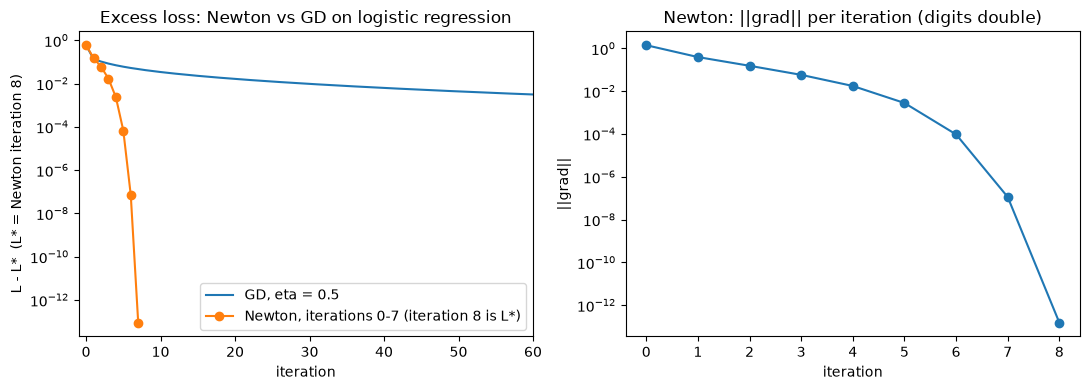

start x0 = +1.0:  +1.5000000000  +1.4166666667  +1.4142156863  +1.4142135624  +1.4142135624   -> f''(x) = +2.83 (minimum)
start x0 = -1.0:  -1.5000000000  -1.4166666667  -1.4142156863  -1.4142135624  -1.4142135624   -> f''(x) = -2.83 (MAXIMUM)
errors from x0 = 1 are squared each step: ratio e_(k+1)/e_k^2 -> 1/(2 sqrt 2) = 0.3536


In [18]:
w = np.zeros(Xb.shape[1]); newton_losses = [log_loss(w)]; grad_norms = [np.linalg.norm(log_grad(w))]
for k in range(8):
    w = w - np.linalg.solve(log_hess(w), log_grad(w))
    newton_losses.append(log_loss(w)); grad_norms.append(np.linalg.norm(log_grad(w)))
w_newton = w.copy()
print("Newton: gradient norm per iteration")
for k, gnorm in enumerate(grad_norms):
    print(f"  iteration {k}: ||grad|| = {gnorm:.2e}   loss = {newton_losses[k]:.6f}")

clf = LogisticRegression(C=1 / (lam_ridge * len(y_bc)), tol=1e-10, max_iter=10000).fit(X_std, y_bc)
w_sklearn = np.r_[clf.intercept_, clf.coef_.ravel()]
print(f"\nmax |w_newton - w_sklearn(lbfgs)| = {np.abs(w_newton - w_sklearn).max():.2e}   (sklearn needed {clf.n_iter_[0]} L-BFGS iterations)")

gd_path = optimise(log_grad, np.zeros(Xb.shape[1]), "gd", 0.5, 300)
gd_losses = np.array([log_loss(v) for v in gd_path])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(gd_losses - newton_losses[-1], label="GD, eta = 0.5")
ax[0].semilogy(np.array(newton_losses[:-1]) - newton_losses[-1], "o-", label="Newton, iterations 0-7 (iteration 8 is L*)")
ax[0].set_title("Excess loss: Newton vs GD on logistic regression"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("L - L*  (L* = Newton iteration 8)"); ax[0].set_xlim(-1, 60); ax[0].legend()
ax[1].semilogy(grad_norms, "o-"); ax[1].set_title("Newton: ||grad|| per iteration (digits double)"); ax[1].set_xlabel("iteration"); ax[1].set_ylabel("||grad||")
plt.tight_layout(); plt.show()

# Newton on f(x) = x^3/3 - 2x  (f' = x^2 - 2, f'' = 2x): minimum at +sqrt(2), maximum at -sqrt(2)
for x_start in [1.0, -1.0]:
    xk = x_start; print(f"start x0 = {x_start:+.1f}:", end="")
    for k in range(5):
        xk = xk - (xk ** 2 - 2) / (2 * xk)
        print(f"  {xk:+.10f}", end="")
    print(f"   -> f''(x) = {2 * xk:+.2f} ({'minimum' if xk > 0 else 'MAXIMUM'})")
print(f"errors from x0 = 1 are squared each step: ratio e_(k+1)/e_k^2 -> 1/(2 sqrt 2) = {1 / (2 * np.sqrt(2)):.4f}")

Notice the signature of quadratic convergence: the exponent of the gradient norm goes
$0, -1, -1, -2, -2, -3, -5, -7, -13$ — once the iterate is close, the number of correct digits doubles
per step. Eight $31\times31$ solves beat 300 gradient steps. The catch is cost: forming $H$ is
$O(nd^2)$ and solving is $O(d^3)$, impossible for $d = 10^8$; and far from the optimum $H$ may be
indefinite. The 1-D run at the end of the cell shows the other caveat: from $x_0 = -1$ Newton
converges, just as fast, to the *maximum* of $f$ — it solves $f' = 0$ and does not know the difference.

**Try it yourself:** replace `np.linalg.solve(log_hess(w), log_grad(w))` by a *damped* step
`np.linalg.solve(log_hess(w) + 1.0 * np.eye(31), log_grad(w))`. Convergence becomes linear instead of
quadratic — this is the Levenberg–Marquardt idea, trading speed for robustness far from the optimum.

## 7. Constrained optimisation: the tangency picture

Minimise $f(x, y) = x^2 + 2y^2$ subject to $h(x, y) = x + y - 3 = 0$. At the constrained optimum the
level set of $f$ is *tangent* to the constraint line, so $\nabla f = -\lambda \nabla h$. Solving the
linear KKT system

$$
\begin{pmatrix} 2 & 0 & 1 \\ 0 & 4 & 1 \\ 1 & 1 & 0 \end{pmatrix}
\begin{pmatrix} x \\ y \\ \lambda \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \\ 3 \end{pmatrix}
$$

gives $(x^\star, y^\star, \lambda) = (2, 1, -4)$ and $f^\star = 6$. We verify the shadow-price
interpretation $\mathrm{d}f^\star/\mathrm{d}b = -\lambda$ by nudging the constraint level, and
we solve the same problem by **projected gradient descent** (step, then project back onto the line).

KKT solution: x* = 2.000, y* = 1.000, lambda = -4.000, f* = 6.000
grad f = [4. 4.],  grad h = [1. 1.]  -> parallel (ratio 4.0)
shadow price: (f*(3.01) - f*(2.99)) / 0.02 = 4.000  vs  -lambda = 4.000
projected GD after 40 steps: [2. 1.]


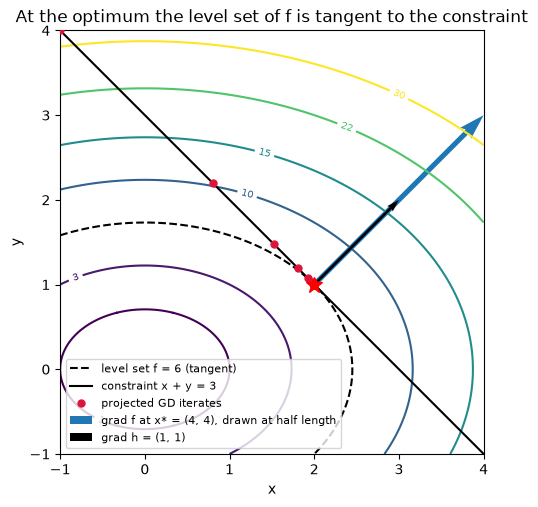

In [19]:
K = np.array([[2.0, 0.0, 1.0], [0.0, 4.0, 1.0], [1.0, 1.0, 0.0]])
x_s, y_s, lam_s = np.linalg.solve(K, np.array([0.0, 0.0, 3.0]))
f_con = lambda p: p[0] ** 2 + 2 * p[1] ** 2
print(f"KKT solution: x* = {x_s:.3f}, y* = {y_s:.3f}, lambda = {lam_s:.3f}, f* = {f_con((x_s, y_s)):.3f}")
print(f"grad f = {np.array([2 * x_s, 4 * y_s])},  grad h = [1. 1.]  -> parallel (ratio {2 * x_s:.1f})")

def f_star(b):          # optimal value as a function of the constraint level  x + y = b
    sol = np.linalg.solve(K, np.array([0.0, 0.0, b])); return f_con(sol[:2])
print(f"shadow price: (f*(3.01) - f*(2.99)) / 0.02 = {(f_star(3.01) - f_star(2.99)) / 0.02:.3f}  vs  -lambda = {-lam_s:.3f}")

# projected gradient descent: step, then project onto the line x + y = 3
a_vec = np.array([1.0, 1.0])
def project_onto_line(p, a=a_vec, b=3.0):
    return p - (a @ p - b) / (a @ a) * a
p = np.array([-1.0, 4.0]); pgd_path = [p.copy()]
for _ in range(40):
    p = project_onto_line(p - 0.2 * np.array([2 * p[0], 4 * p[1]])); pgd_path.append(p.copy())
pgd_path = np.array(pgd_path)
print(f"projected GD after 40 steps: {pgd_path[-1]}")

G1, G2 = np.meshgrid(np.linspace(-1, 4, 301), np.linspace(-1, 4, 301))
plt.figure(figsize=(6, 5.5))
cs = plt.contour(G1, G2, G1 ** 2 + 2 * G2 ** 2, levels=[1, 3, 10, 15, 22, 30], cmap="viridis")
plt.clabel(cs, fmt="%.0f", fontsize=7)
plt.contour(G1, G2, G1 ** 2 + 2 * G2 ** 2, levels=[6], colors="k", linestyles="--", linewidths=1.5)
plt.plot([], [], "k--", lw=1.5, label="level set f = 6 (tangent)")          # legend entry for the contour above
xx = np.linspace(-1, 4, 50); plt.plot(xx, 3 - xx, "k-", lw=1.5, label="constraint x + y = 3")
plt.plot(pgd_path[:, 0], pgd_path[:, 1], "o", color="crimson", ms=5, lw=0, zorder=5, label="projected GD iterates")
# grad f = (4, 4) drawn at half length, grad h = (1, 1) at full length on top: same direction, different lengths
plt.quiver(x_s, y_s, 2 * x_s, 4 * y_s, angles="xy", scale_units="xy", scale=2, width=0.012, color="tab:blue",
           label="grad f at x* = (4, 4), drawn at half length")
plt.quiver(x_s, y_s, 1, 1, angles="xy", scale_units="xy", scale=1, width=0.006, color="k", zorder=4, label="grad h = (1, 1)")
plt.plot(x_s, y_s, "r*", ms=12, zorder=6)
plt.title("At the optimum the level set of f is tangent to the constraint"); plt.xlabel("x"); plt.ylabel("y")
plt.legend(fontsize=8, loc="lower left"); plt.gca().set_aspect("equal"); plt.show()

Notice that the dashed level set $f = 6$ touches the constraint line at exactly one point, and the two
gradient arrows there point the same way (the blue one is drawn at half its length, so it is still twice
as long as the black one): $\nabla f = (4, 4) = 4\,\nabla h$, so $\lambda = -4$ in the
convention $\nabla f + \lambda\nabla h = 0$. The shadow price checks out: moving the constraint level
from 3 to 3.01 raises the minimal cost by about $0.04 = -\lambda \times 0.01$. Projected GD finds the same point
without ever forming the Lagrangian — the approach used when the constraint set is simple (a
box, a sphere, the probability simplex).

**Try it yourself:** change the constraint to an *inequality* $x + y \ge 3$ by projecting only when
$x + y < 3$. Start at $(3, 3)$ — the constraint is inactive there and projected GD walks to the
unconstrained minimum $(0, 0)$ until it hits the line, then slides along it to $(2, 1)$.

## 8. Practical diagnostics: schedules, the range test, clipping, early stopping

Four tools, one figure each.

1. **Learning-rate schedules** — step decay, cosine, and warm-up + cosine, as functions of the step.
2. **The learning-rate range test** — run GD while increasing $\eta$ geometrically and watch the loss;
   the knee where it starts climbing is $2/L$, so the recommended $\eta$ is a few times less.
3. **Gradient clipping by global norm** — $g \leftarrow g\,\min(1, c/\lVert g\rVert)$ keeps the direction
   and bounds the step.
4. **Early stopping** — train on 120 of the 569 tumours and validate on the rest: the training loss
   keeps falling, the validation loss turns around.

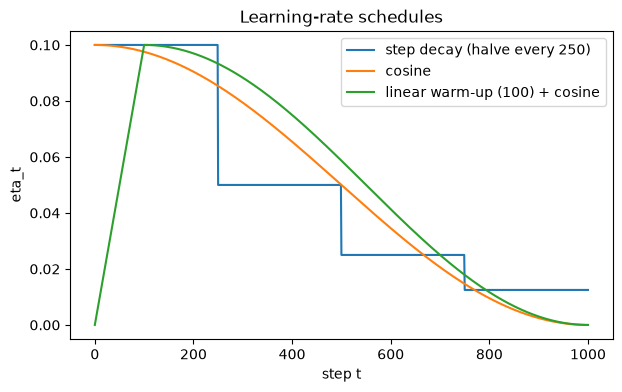

cosine schedule: eta at T/4 = 0.854 eta_max,  at T/2 = 0.500 eta_max,  at 3T/4 = 0.146 eta_max
range test: lowest loss at eta = 0.218; loss has doubled by eta = 0.239;  theory 2/L = 0.285;  a safe starting point is 1/L = 0.143


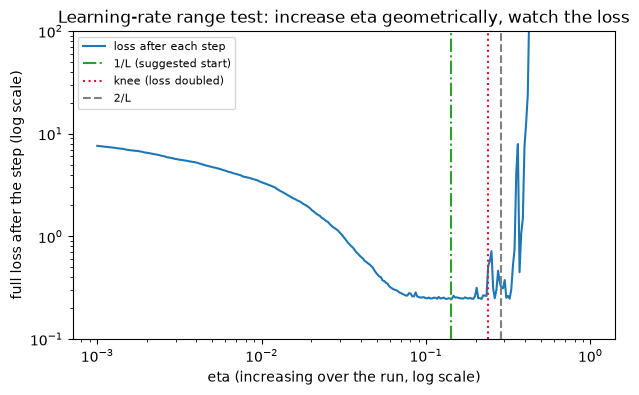

In [20]:
T, T_warm, eta_max = 1000, 100, 0.1
t = np.arange(T + 1)
step_decay = eta_max * 0.5 ** np.minimum(t // 250, 3)       # four levels; t = T stays on the last one
cosine = 0.5 * eta_max * (1 + np.cos(np.pi * t / T))
warm_cos = np.where(t < T_warm, eta_max * t / T_warm, 0.5 * eta_max * (1 + np.cos(np.pi * np.clip(t - T_warm, 0, None) / (T - T_warm))))
plt.plot(t, step_decay, label="step decay (halve every 250)"); plt.plot(t, cosine, label="cosine"); plt.plot(t, warm_cos, label="linear warm-up (100) + cosine")
plt.title("Learning-rate schedules"); plt.xlabel("step t"); plt.ylabel("eta_t"); plt.legend(); plt.show()
print(f"cosine schedule: eta at T/4 = {0.5 * (1 + np.cos(np.pi / 4)):.3f} eta_max,  at T/2 = {0.5:.3f} eta_max,  at 3T/4 = {0.5 * (1 + np.cos(3 * np.pi / 4)):.3f} eta_max")

# learning-rate range test on the linear-regression problem of Section 4 (true 2/L is known),
# run the realistic way: with mini-batches of 32, one step per candidate eta, eta growing geometrically
etas_test = np.logspace(-3, 0, 300)
r = np.random.default_rng(0); w = np.zeros(d); range_losses = []
for e in etas_test:
    idx = r.choice(n, size=32, replace=False)
    w = w - e * grad_batch(w, idx); range_losses.append(mse(w))
range_losses = np.array(range_losses)
i_min = int(np.argmin(range_losses))
knee = etas_test[i_min + int(np.argmax(range_losses[i_min:] > 2 * range_losses.min()))]
print(f"range test: lowest loss at eta = {etas_test[i_min]:.3f}; loss has doubled by eta = {knee:.3f};  theory 2/L = {2 / L_lin:.3f};  a safe starting point is 1/L = {1 / L_lin:.3f}")
plt.loglog(etas_test, range_losses, label="loss after each step")
plt.axvline(1 / L_lin, color="tab:green", ls="-.", label="1/L (suggested start)")
plt.axvline(knee, color="crimson", ls=":", label="knee (loss doubled)")
plt.axvline(2 / L_lin, color="gray", ls="--", label="2/L")
plt.ylim(0.1, 100); plt.title("Learning-rate range test: increase eta geometrically, watch the loss")
plt.xlabel("eta (increasing over the run, log scale)"); plt.ylabel("full loss after the step (log scale)"); plt.legend(fontsize=8); plt.show()

Notice that the loss falls from its starting value, is flat and minimal over a wide band, and shoots
up by orders of magnitude close to $2/L$ — the range test *measures* the curvature constant $L$ you would
otherwise have to guess. The green line, $1/L$, sits inside the flat band, a safe distance below the knee. The mini-batch noise is
what makes the knee visible: with full-batch GD on an already-converged iterate, an unstable step
needs several iterations before the error in the stiff direction has grown enough to see, so the
knee appears late. On a non-quadratic loss the knee is less sharp, but the recipe is the same:
pick a value a few times below it.

In [21]:
def clip_by_global_norm(g, c):
    norm = np.linalg.norm(g)
    return g * min(1.0, c / norm) if norm > 0 else g

g = np.array([3.0, 4.0])
print(f"g = {g}, ||g|| = {np.linalg.norm(g):.1f}  ->  clipped at c = 1: {clip_by_global_norm(g, 1.0)}  (norm {np.linalg.norm(clip_by_global_norm(g, 1.0)):.1f}, same direction)")

# clipping rescues a too-large step on the rotated quadratic of Section 3
for eta in [0.5, 1.0]:
    for c in [None, 2.0]:
        th = Q @ np.array([8.0, 2.0]); diverged = False
        for _ in range(200):
            gq = A @ th
            th = th - eta * (gq if c is None else clip_by_global_norm(gq, c))
            if not np.isfinite(th).all() or np.linalg.norm(th) > 1e6:
                diverged = True; break
        print(f"eta = {eta}, clip = {c}: {'DIVERGED' if diverged else f'||theta_200|| = {np.linalg.norm(th):.3f}'}")

g = [3. 4.], ||g|| = 5.0  ->  clipped at c = 1: [0.6 0.8]  (norm 1.0, same direction)
eta = 0.5, clip = None: DIVERGED
eta = 0.5, clip = 2.0: ||theta_200|| = 0.464
eta = 1.0, clip = None: DIVERGED
eta = 1.0, clip = 2.0: ||theta_200|| = 1.115


Four printed lines do not show *where* the clipped iterate goes. We draw the run with $\eta = 0.5$
and $c = 2$ next to the unclipped one, and follow both eigen-coordinates (flat, stiff) of the clipped
runs for $\eta = 0.5$ and $\eta = 1$.

unclipped, eta = 0.5: ||theta_k|| for k = 0..5 = [   8.2    8.9   32.1  128.   512.  2048. ]
clipped, eta = 0.5: flat coordinate -> -1.1e-16;  stiff coordinate bounces between -0.536 and +0.464, a jump of 1.000 = eta * c
clipped, eta = 1.0: flat coordinate -> +5.6e-17;  stiff coordinate bounces between +0.885 and -1.115, a jump of 2.000 = eta * c


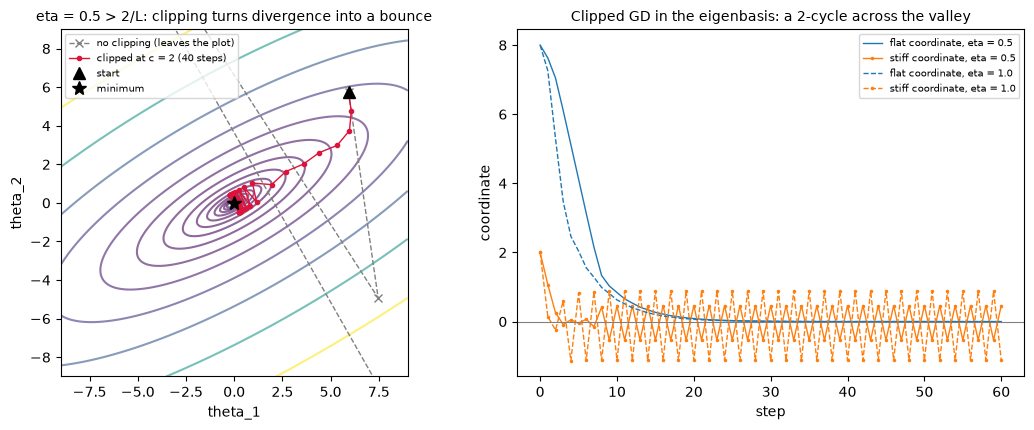

In [22]:
def run_clipped(eta, c, steps):
    th = Q @ np.array([8.0, 2.0]); path_c = [th]
    for _ in range(steps):
        gq = A @ th
        th = th - eta * (gq if c is None else clip_by_global_norm(gq, c)); path_c.append(th)
        if np.linalg.norm(th) > 1e3:                    # unclipped runs: stop once they have clearly left
            break
    return np.array(path_c)

pc, pn = run_clipped(0.5, 2.0, 40), run_clipped(0.5, None, 40)
print("unclipped, eta = 0.5: ||theta_k|| for k = 0..5 =", np.round(np.linalg.norm(pn[:6], axis=1), 1))
for eta in [0.5, 1.0]:
    z = run_clipped(eta, 2.0, 200) @ Q                  # rows are (flat, stiff) eigen-coordinates
    print(f"clipped, eta = {eta}: flat coordinate -> {z[-1, 0]:+.1e};  stiff coordinate bounces between "
          f"{z[-2, 1]:+.3f} and {z[-1, 1]:+.3f}, a jump of {abs(z[-1, 1] - z[-2, 1]):.3f} = eta * c")

Gx, Gy = np.meshgrid(np.linspace(-9, 9, 181), np.linspace(-9, 9, 181))
Zq = 0.5 * (A[0, 0] * Gx ** 2 + 2 * A[0, 1] * Gx * Gy + A[1, 1] * Gy ** 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].contour(Gx, Gy, Zq, levels=np.logspace(-1, 2.6, 14), cmap="viridis", alpha=0.6)
ax[0].plot(pn[:4, 0], pn[:4, 1], "x--", color="gray", lw=1, label="no clipping (leaves the plot)")
ax[0].plot(pc[:, 0], pc[:, 1], "o-", color="crimson", ms=3, lw=1, label="clipped at c = 2 (40 steps)")
ax[0].plot(*pc[0], "k^", ms=8, label="start"); ax[0].plot(0, 0, "k*", ms=10, label="minimum")
ax[0].set_xlim(-9, 9); ax[0].set_ylim(-9, 9); ax[0].set_aspect("equal")
ax[0].set_title("eta = 0.5 > 2/L: clipping turns divergence into a bounce", fontsize=10)
ax[0].set_xlabel("theta_1"); ax[0].set_ylabel("theta_2"); ax[0].legend(fontsize=7, loc="upper left")
for eta, ls in [(0.5, "-"), (1.0, "--")]:
    z = run_clipped(eta, 2.0, 60) @ Q
    ax[1].plot(z[:, 0], ls, color="tab:blue", lw=1, label=f"flat coordinate, eta = {eta}")
    ax[1].plot(z[:, 1], ls, color="tab:orange", marker=".", ms=3, lw=1, label=f"stiff coordinate, eta = {eta}")
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_title("Clipped GD in the eigenbasis: a 2-cycle across the valley", fontsize=10)
ax[1].set_xlabel("step"); ax[1].set_ylabel("coordinate"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Notice that** clipping caps the instability rather than removing it. While $\lVert g\rVert > c$ every
step has length exactly $\eta c = 1$, so the iterate walks steadily down the valley; near the minimum
the stiff coordinate still wants to grow by $\lvert 1 - 0.5\cdot10\rvert = 4$ per step, is clipped back,
and ends in a two-step bounce between $-0.54$ and $+0.46$ (between $+0.88$ and $-1.12$ for $\eta = 1$),
a jump of exactly $\eta c$, while the flat coordinate converges. The printed $\lVert\theta_{200}\rVert$
values above are just one end of each bounce. Without clipping the same run passes
$\lVert\theta\rVert = 2000$ after five steps. Turning an explosion into a bounded bounce is exactly what
you want when a single bad mini-batch would otherwise destroy a week of training — but clipping cannot
make a step $\eta > 2/L$ converge.
Clipping handles spikes; the learning rate handles curvature.

best validation loss 0.1486 at step 92; final validation loss 0.3643; training loss keeps falling to 0.0043
early stopping with patience 100 would stop at step 192 and restore step 92


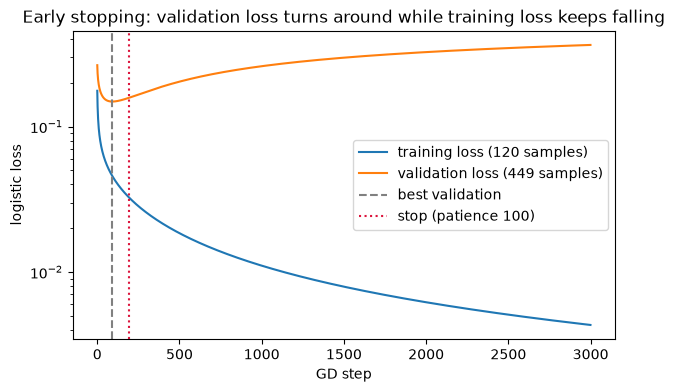

In [23]:
perm = rng.permutation(len(y_bc)); train_idx, val_idx = perm[:120], perm[120:]
w = np.zeros(Xb.shape[1]); train_curve, val_curve = [], []
for k in range(3000):
    w = w - 0.5 * (Xb[train_idx].T @ (sigmoid(Xb[train_idx] @ w) - y_bc[train_idx]) / len(train_idx))   # no ridge term this time
    train_curve.append(log_loss(w, Xb[train_idx], y_bc[train_idx]) - 0.5 * lam_ridge * (w[1:] @ w[1:]))
    val_curve.append(log_loss(w, Xb[val_idx], y_bc[val_idx]) - 0.5 * lam_ridge * (w[1:] @ w[1:]))
val_curve = np.array(val_curve); best = int(np.argmin(val_curve))
patience, stop_at = 100, None
for k in range(len(val_curve)):
    if k - int(np.argmin(val_curve[:k + 1])) >= patience:
        stop_at = k; break
print(f"best validation loss {val_curve[best]:.4f} at step {best}; final validation loss {val_curve[-1]:.4f}; training loss keeps falling to {train_curve[-1]:.4f}")
print(f"early stopping with patience {patience} would stop at step {stop_at} and restore step {int(np.argmin(val_curve[:stop_at + 1]))}")
plt.semilogy(train_curve, label="training loss (120 samples)"); plt.semilogy(val_curve, label="validation loss (449 samples)")
plt.axvline(best, color="gray", ls="--", label="best validation"); plt.axvline(stop_at, color="crimson", ls=":", label=f"stop (patience {patience})")
plt.title("Early stopping: validation loss turns around while training loss keeps falling"); plt.xlabel("GD step"); plt.ylabel("logistic loss"); plt.legend(); plt.show()

Notice that the unregularised model fitted on 120 samples drives its training loss towards zero
while the validation loss bottoms out early and then rises — overfitting, visible as a curve.
Stopping at the validation minimum is both a stopping rule and a regulariser; Module 13 makes the
link to ridge regression precise (for a quadratic loss, GD stopped at step $k$ behaves like ridge
with $\lambda \approx 1/(\eta k)$).

**Try it yourself:** put the ridge term back into the gradient (`+ lam_ridge * w[1:]`). The
validation curve should flatten instead of turning up.

## Summary

* A learning problem is $\min_\theta L(\theta)$; stationary points include saddles, and in high
  dimensions saddles, not local minima, are what slow training down.
* Convexity ($\nabla^2 L \succeq 0$) makes every stationary point a global minimum; linear and
  logistic regression are convex, neural networks are not.
* On a quadratic, GD converges iff $\eta < 2/L$, fastest at $\eta = 2/(L+\mu)$ with rate
  $(\kappa-1)/(\kappa+1)$; the step count is linear in $\kappa$, and $\kappa$ is set by feature scaling.
* Mini-batch gradients are unbiased with variance $\propto 1/b$; a constant step leaves a noise
  ball of variance $\approx \eta\sigma^2/(2\lambda)$, which schedules shrink.
* Momentum accumulates along-valley velocity ($\sqrt\kappa$ instead of $\kappa$); RMSProp and Adam give
  each parameter its own step; Adam's bias correction makes its first step $\eta\,\mathrm{sign}(g)$ (up to $\epsilon$)
  and keeps the early steps $\approx\eta$.
* Newton's method squares the error each iteration but costs $O(d^3)$; L-BFGS is the practical
  version, and it is what `LogisticRegression` runs.
* At a constrained optimum the level set is tangent to the constraint: $\nabla f + \lambda\nabla h = 0$;
  the multiplier is the shadow price, and KKT adds $\mu \ge 0$ and complementary slackness.
* Read the loss and gradient-norm curves: range test for $\eta$, warm-up and decay, clipping for
  spikes, early stopping for overfitting.

**Next: open `exercises.ipynb`** and implement these pieces yourself.